# Modeling Guilty Minds: NLP, Random Forest & SHAP Analysis
## Complementary Machine Learning Analyses for the MPC Mental State Study
### David George Kamper, Andrew Bistras, Keith J. Holyoak, Jaime Castrellon

This notebook provides non-parametric and NLP-based analyses that complement the
cumulative link mixed models (CLMMs) in the R analysis. It covers:

1. **Random Forest classification** of culpability judgments from vignette features (with and without the risk slider)
2. **SHAP feature importance** — global, per-class, and interaction effects
3. **Sentence-transformer embeddings** of vignette texts using BGE-large (primary) and MiniLM (robustness check)
4. **UMAP dimensionality reduction** of the embedding space
5. **Representational similarity analysis** — do semantic distances predict judgment distances? (full-text and clause-level)
6. **Free-text justification analysis** — embeddings, BERTopic, and text-to-judgment classification
7. **Publication-quality grayscale figures** for all key results

## 0. Environment Setup

In [1]:
# ── Install all required packages ──
!pip install -q sentence-transformers umap-learn hdbscan bertopic shap scikit-learn \
    matplotlib seaborn pandas numpy scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 6.2 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist, squareform
import warnings
import json
import re
import os

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, cohen_kappa_score)
from sklearn.preprocessing import LabelEncoder

import shap
from sentence_transformers import SentenceTransformer
import umap

# BERTopic import — may fail on some Colab runtimes if torch is not GPU-enabled,
# so we wrap in try/except and fall back gracefully.
try:
    from bertopic import BERTopic
    BERTOPIC_AVAILABLE = True
except ImportError:
    BERTOPIC_AVAILABLE = False
    print("BERTopic not available; skipping topic modeling cells.")

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Reproducibility
SEED = 2026
np.random.seed(SEED)

# Publication figure defaults: grayscale, clean, no titles (titles go in captions).
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': 'black',
    'axes.linewidth': 0.8,
})

print("All imports loaded successfully.")

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


All imports loaded successfully.


## 1. Data Loading & Preprocessing

Load the same CSV used by the R analysis. Apply identical exclusion criteria:
drop participants who did not complete all 5 vignettes. Derive the same binary
feature columns and ordinal culpability score.

In [3]:
# ── Mount Google Drive ──
from google.colab import drive
drive.mount('/content/drive')

CSV_PATH = (
    "/content/drive/MyDrive/DGK Lab/Reasoning Lab/"
    "DGK Lab - Mens Rea /Data/modeling_mental_states_analysis_part3.csv"
)

JSON_PATH = (
    "/content/drive/MyDrive/DGK Lab/Castrellon Lab/"
    "DGK Lab - Mens Rea /Analysis/NLP/mensReaVignettes_binary.json"
)

raw = pd.read_csv(CSV_PATH)
print(f"Raw dataset: {len(raw)} rows, {raw['session_id'].nunique()} unique sessions")

# Load ground-truth vignette templates from the experiment JSON.
with open(JSON_PATH, 'r') as f:
    vignette_json = json.load(f)
print(f"Loaded {len(vignette_json)} vignette templates from JSON")

Mounted at /content/drive
Raw dataset: 1081 rows, 230 unique sessions
Loaded 64 vignette templates from JSON


In [4]:
# ── Exclusion: keep only participants with exactly 5 trials ──
completions = raw.groupby('session_id').size().reset_index(name='n_trials')
complete_ids = completions.loc[completions['n_trials'] == 5, 'session_id']
d = raw[raw['session_id'].isin(complete_ids)].copy()
print(f"Post-exclusion: {len(d)} trials from {d['session_id'].nunique()} participants")

# ── Derive analysis variables ──
# Ordinal culpability score: same 1-4 mapping as the R analysis.
culp_map = {'Blamelessness': 1, 'Negligence': 2, 'Recklessness': 3, 'Knowledge': 4}
d['culpability'] = d['judgment'].map(culp_map)

# Binary feature columns: 1 = the theoretically more incriminating level.
d['source_bin']   = (d['source']   == 'biker').astype(int)
d['package_bin']  = (d['package']  == 'duffel_bag').astype(int)
d['inquiry_bin']  = (d['inquiry']  == 'source_tells').astype(int)
d['payment'] = d['payment'].str.replace(',', '').str.strip()
d['payment_bin']  = (d['payment']  == '$1000').astype(int)
d['location_bin'] = (d['location'] == 'Mexico').astype(int)
d['contents_bin'] = (d['contents'] == 'fentanyl').astype(int)

# Readable labels for feature columns (used in SHAP plots).
FEATURE_COLS = ['slider_value', 'source_bin', 'package_bin', 'inquiry_bin',
                'payment_bin', 'location_bin', 'contents_bin']
FEATURE_LABELS = ['Risk Slider', 'Source (biker)', 'Package (duffel)',
                  'Inquiry (told)', 'Payment ($1000)', 'Location (Mexico)',
                  'Contents (fentanyl)']
LABEL_MAP = dict(zip(FEATURE_COLS, FEATURE_LABELS))

# Judgment labels in ordinal order.
JUDGMENT_ORDER = ['Blamelessness', 'Negligence', 'Recklessness', 'Knowledge']

print(f"Features: {FEATURE_COLS}")
print(f"Judgment distribution:\n{d['judgment'].value_counts().reindex(JUDGMENT_ORDER)}")

Post-exclusion: 1060 trials from 212 participants
Features: ['slider_value', 'source_bin', 'package_bin', 'inquiry_bin', 'payment_bin', 'location_bin', 'contents_bin']
Judgment distribution:
judgment
Blamelessness    177
Negligence       452
Recklessness     286
Knowledge        145
Name: count, dtype: int64


## 2. Vignette Text Reconstruction

We load the ground-truth vignette templates from the experiment's JSON file
(`mensReaVignettes_binary.json`), which contains the exact text shown to
participants. Each template has three placeholders — `[NAME]`, `[CANADA_LOC]`,
and `[MEXICO_LOC]` — which the experiment replaced with randomized names and
city names on each trial. Since these replacements were random and not part of
the experimental manipulation, we substitute fixed constants ("John",
"Winnipeg, Canada", "Nogales, Mexico") so that embedding distances reflect
only the 6 manipulated features.

We also retain a reconstruction function for mapping the CSV feature columns
back to vignette text, and cross-validate it against the JSON to verify
consistency.

Binary encoding (right-to-left): bit 0 = contents, bit 1 = source, bit 2 = package,
bit 3 = inquiry, bit 4 = payment, bit 5 = location.

**Note on previous versions:** An earlier version of this notebook reconstructed
vignette text from the feature columns using a template function. Cross-validation
against the experiment JSON revealed several wording discrepancies (e.g.,
"gift-wrapped" vs "gift wrapped", presence/absence of "comes across his uncle").
The current version embeds directly from the JSON to ensure fidelity to the
stimulus text participants actually read.

In [5]:
# ── Build vignette texts from ground-truth JSON ──
# Replace placeholders with fixed constants. The specific name and city were
# randomized per-trial and are not part of the manipulation.

def fill_template(template):
    """Replace JSON placeholders with fixed constants."""
    return (template
            .replace('[NAME]', 'John')
            .replace('[CANADA_LOC]', 'Winnipeg, Canada')
            .replace('[MEXICO_LOC]', 'Nogales, Mexico'))

# Build lookup: binary ID string -> filled text
json_text_lookup = {}
for v in vignette_json:
    vid = v['id']
    # Pad to 6 digits (some IDs may have leading zeros stripped)
    vid_padded = vid.zfill(6)
    json_text_lookup[vid_padded] = fill_template(v['vignette'])

print(f"JSON lookup built: {len(json_text_lookup)} vignettes")

# ── Map each trial to its vignette text via the binary ID ──
# The vignette_id column in the CSV is the decimal or binary ID.
# We need to convert to 6-bit binary string to match the JSON keys.
def to_bin6(vid):
    """Convert vignette ID (int or string) to zero-padded 6-bit binary string."""
    return format(int(str(vid), 2) if len(str(vid)) > 3 else int(vid), '06b') \
        if str(vid).isdigit() else str(vid).zfill(6)

# Actually, the vignette_id in CSV appears to be the binary string itself
# (e.g., '1010', '10010', '111001'). Let's just zero-pad it.
d['vignette_id_bin'] = d['vignette_id'].astype(str).str.zfill(6)
d['vignette_text'] = d['vignette_id_bin'].map(json_text_lookup)

# Verify all trials got a text match
n_matched = d['vignette_text'].notna().sum()
n_total = len(d)
print(f"Matched {n_matched}/{n_total} trials to JSON vignette text")
if n_matched < n_total:
    missing = d[d['vignette_text'].isna()]['vignette_id_bin'].unique()
    print(f"  WARNING: Missing IDs: {missing[:10]}")

# ── Build unique vignette table ──
feature_key_cols = ['source', 'package', 'inquiry', 'payment', 'location', 'contents']
d['vignette_key'] = d[feature_key_cols].astype(str).agg('_'.join, axis=1)

unique_vignettes = d.drop_duplicates(subset='vignette_key')[['vignette_key', 'vignette_text', 'vignette_id_bin']]
print(f"Unique vignette configurations: {len(unique_vignettes)}")
print(f"Sample (first 200 chars):\n{unique_vignettes.iloc[0]['vignette_text'][:200]}...")

JSON lookup built: 64 vignettes
Matched 1060/1060 trials to JSON vignette text
Unique vignette configurations: 64
Sample (first 200 chars):
John is an American citizen who regularly travels to Nogales, Mexico, a town near the U.S. border where John has many relatives.  One night when John is in town, John comes across his uncle, who asks ...


## 3. Sentence-Transformer Embeddings

We embed the unique vignette texts using two models:

1. **Primary: `BAAI/bge-large-en-v1.5`** (1024-dim) — Uses CLS-token pooling and
   was trained with hard-negative contrastive learning, making it specifically
   optimized to distinguish similar texts. This addresses the concern that
   mean-pooling models (like MiniLM) produce near-identical embeddings for
   templated texts where only a few words change.

2. **Robustness check: `all-MiniLM-L6-v2`** (384-dim) — A widely-used lightweight
   model included to demonstrate that our RSA results are (or are not) sensitive
   to embedding model choice.

We report results from both models throughout, with BGE-large as the primary.

In [6]:
# ── Load embedding models ──
# Primary model: BGE-large with CLS pooling and hard-negative contrastive training.
# This is specifically designed to distinguish between similar texts.
st_model_bge = SentenceTransformer('BAAI/bge-large-en-v1.5')

# Robustness check: MiniLM (mean pooling, 384-dim).
st_model_mini = SentenceTransformer('all-MiniLM-L6-v2')

# Use BGE as the default model for all downstream analyses.
st_model = st_model_bge

# ── Embed unique vignette texts with both models ──
unique_texts = unique_vignettes['vignette_text'].tolist()
unique_keys = unique_vignettes['vignette_key'].tolist()

print("Embedding with BGE-large...")
vignette_embeddings_bge = st_model_bge.encode(
    unique_texts, show_progress_bar=True, batch_size=32, normalize_embeddings=True)

print("Embedding with MiniLM...")
vignette_embeddings_mini = st_model_mini.encode(
    unique_texts, show_progress_bar=True, batch_size=32, normalize_embeddings=True)

# Primary embeddings = BGE
vignette_embeddings = vignette_embeddings_bge

# Build lookup dictionaries for both models.
key_to_embedding_bge = dict(zip(unique_keys, vignette_embeddings_bge))
key_to_embedding_mini = dict(zip(unique_keys, vignette_embeddings_mini))
key_to_embedding = key_to_embedding_bge  # default

print(f"BGE embedding shape: {vignette_embeddings_bge.shape}")
print(f"MiniLM embedding shape: {vignette_embeddings_mini.shape}")

# ── Map embeddings back to trial-level data ──
d['embedding'] = d['vignette_key'].map(key_to_embedding)
assert d['embedding'].notna().all(), "Some trials missing embeddings!"
print(f"All {len(d)} trials mapped to embeddings successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

...

Embedding with BGE-large...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embedding with MiniLM...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

BGE embedding shape: (64, 1024)
MiniLM embedding shape: (64, 384)
All 1060 trials mapped to embeddings successfully.


## 4. UMAP Dimensionality Reduction

Project the vignette embeddings into 2D using UMAP. We fit UMAP
on the unique vignette embeddings (not trial-level, since many trials share the
same vignette text), then visualize how the embedding space relates to the
experimental feature structure and to the mean culpability judgments.

**Methodological note:** UMAP projections are sensitive to hyperparameter choices
(n_neighbors, min_dist) and can produce different configurations across runs.
These visualizations are exploratory and intended to complement the quantitative
RSA and classification analyses. They should be interpreted with caution and are
best suited for supplementary material rather than primary figures.

In [7]:
# ── Build vignette-level statistics ──
vignette_stats = d.groupby('vignette_key').agg(
    mean_culp=('culpability', 'mean'),
    mean_risk=('slider_value', 'mean'),
    n_trials=('culpability', 'count'),
    modal_judgment=('judgment', lambda x: x.mode().iloc[0]),
    pct_knowledge=('judgment', lambda x: (x == 'Knowledge').mean()),
    pct_recklessness=('judgment', lambda x: (x == 'Recklessness').mean()),
    source_bin=('source_bin', 'first'),
    package_bin=('package_bin', 'first'),
    inquiry_bin=('inquiry_bin', 'first'),
    payment_bin=('payment_bin', 'first'),
    location_bin=('location_bin', 'first'),
    contents_bin=('contents_bin', 'first'),
).reset_index()

# ── Fit UMAP on unique vignette embeddings (BGE primary) ──
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1,
                     metric='cosine', random_state=SEED)
umap_coords = reducer.fit_transform(vignette_embeddings)

# Merge UMAP coordinates
key_to_umap = dict(zip(unique_keys, umap_coords))
vignette_stats['umap_x'] = vignette_stats['vignette_key'].map(lambda k: key_to_umap[k][0])
vignette_stats['umap_y'] = vignette_stats['vignette_key'].map(lambda k: key_to_umap[k][1])

print(f"UMAP fitted on {len(vignette_embeddings)} unique vignettes (BGE-large).")
print(f"Vignette stats shape: {vignette_stats.shape}")

UMAP fitted on 64 unique vignettes (BGE-large).
Vignette stats shape: (64, 15)


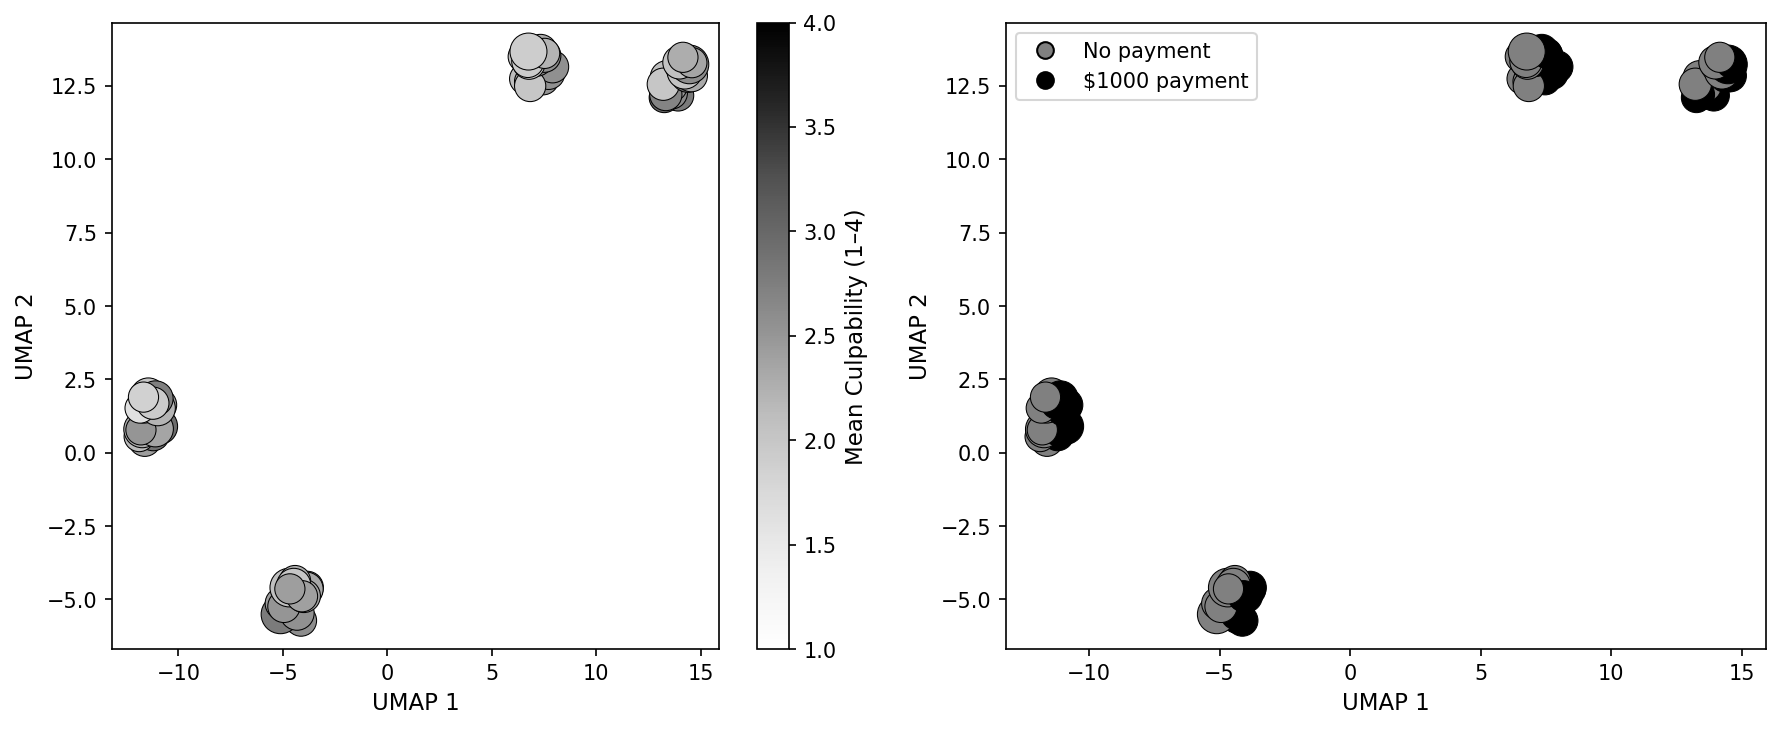

Saved: fig_umap_vignette_space.pdf


In [8]:
# ── UMAP Figure: colored by mean culpability ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel A: Mean culpability
sc = axes[0].scatter(vignette_stats['umap_x'], vignette_stats['umap_y'],
                     c=vignette_stats['mean_culp'], cmap='Greys',
                     s=vignette_stats['n_trials'] * 15, edgecolors='black',
                     linewidth=0.5, vmin=1, vmax=4)
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label('Mean Culpability (1–4)')
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

# Panel B: Colored by payment (the strongest feature predictor from the CLMM)
colors_pay = ['grey' if p == 0 else 'black' for p in vignette_stats['payment_bin']]
axes[1].scatter(vignette_stats['umap_x'], vignette_stats['umap_y'],
                c=colors_pay, s=vignette_stats['n_trials'] * 15,
                edgecolors='black', linewidth=0.5)
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
# Manual legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey',
           markersize=8, label='No payment', markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black',
           markersize=8, label='$1000 payment', markeredgecolor='black'),
]
axes[1].legend(handles=legend_elements, loc='best')

plt.tight_layout()
plt.savefig('fig_umap_vignette_space.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_umap_vignette_space.pdf")

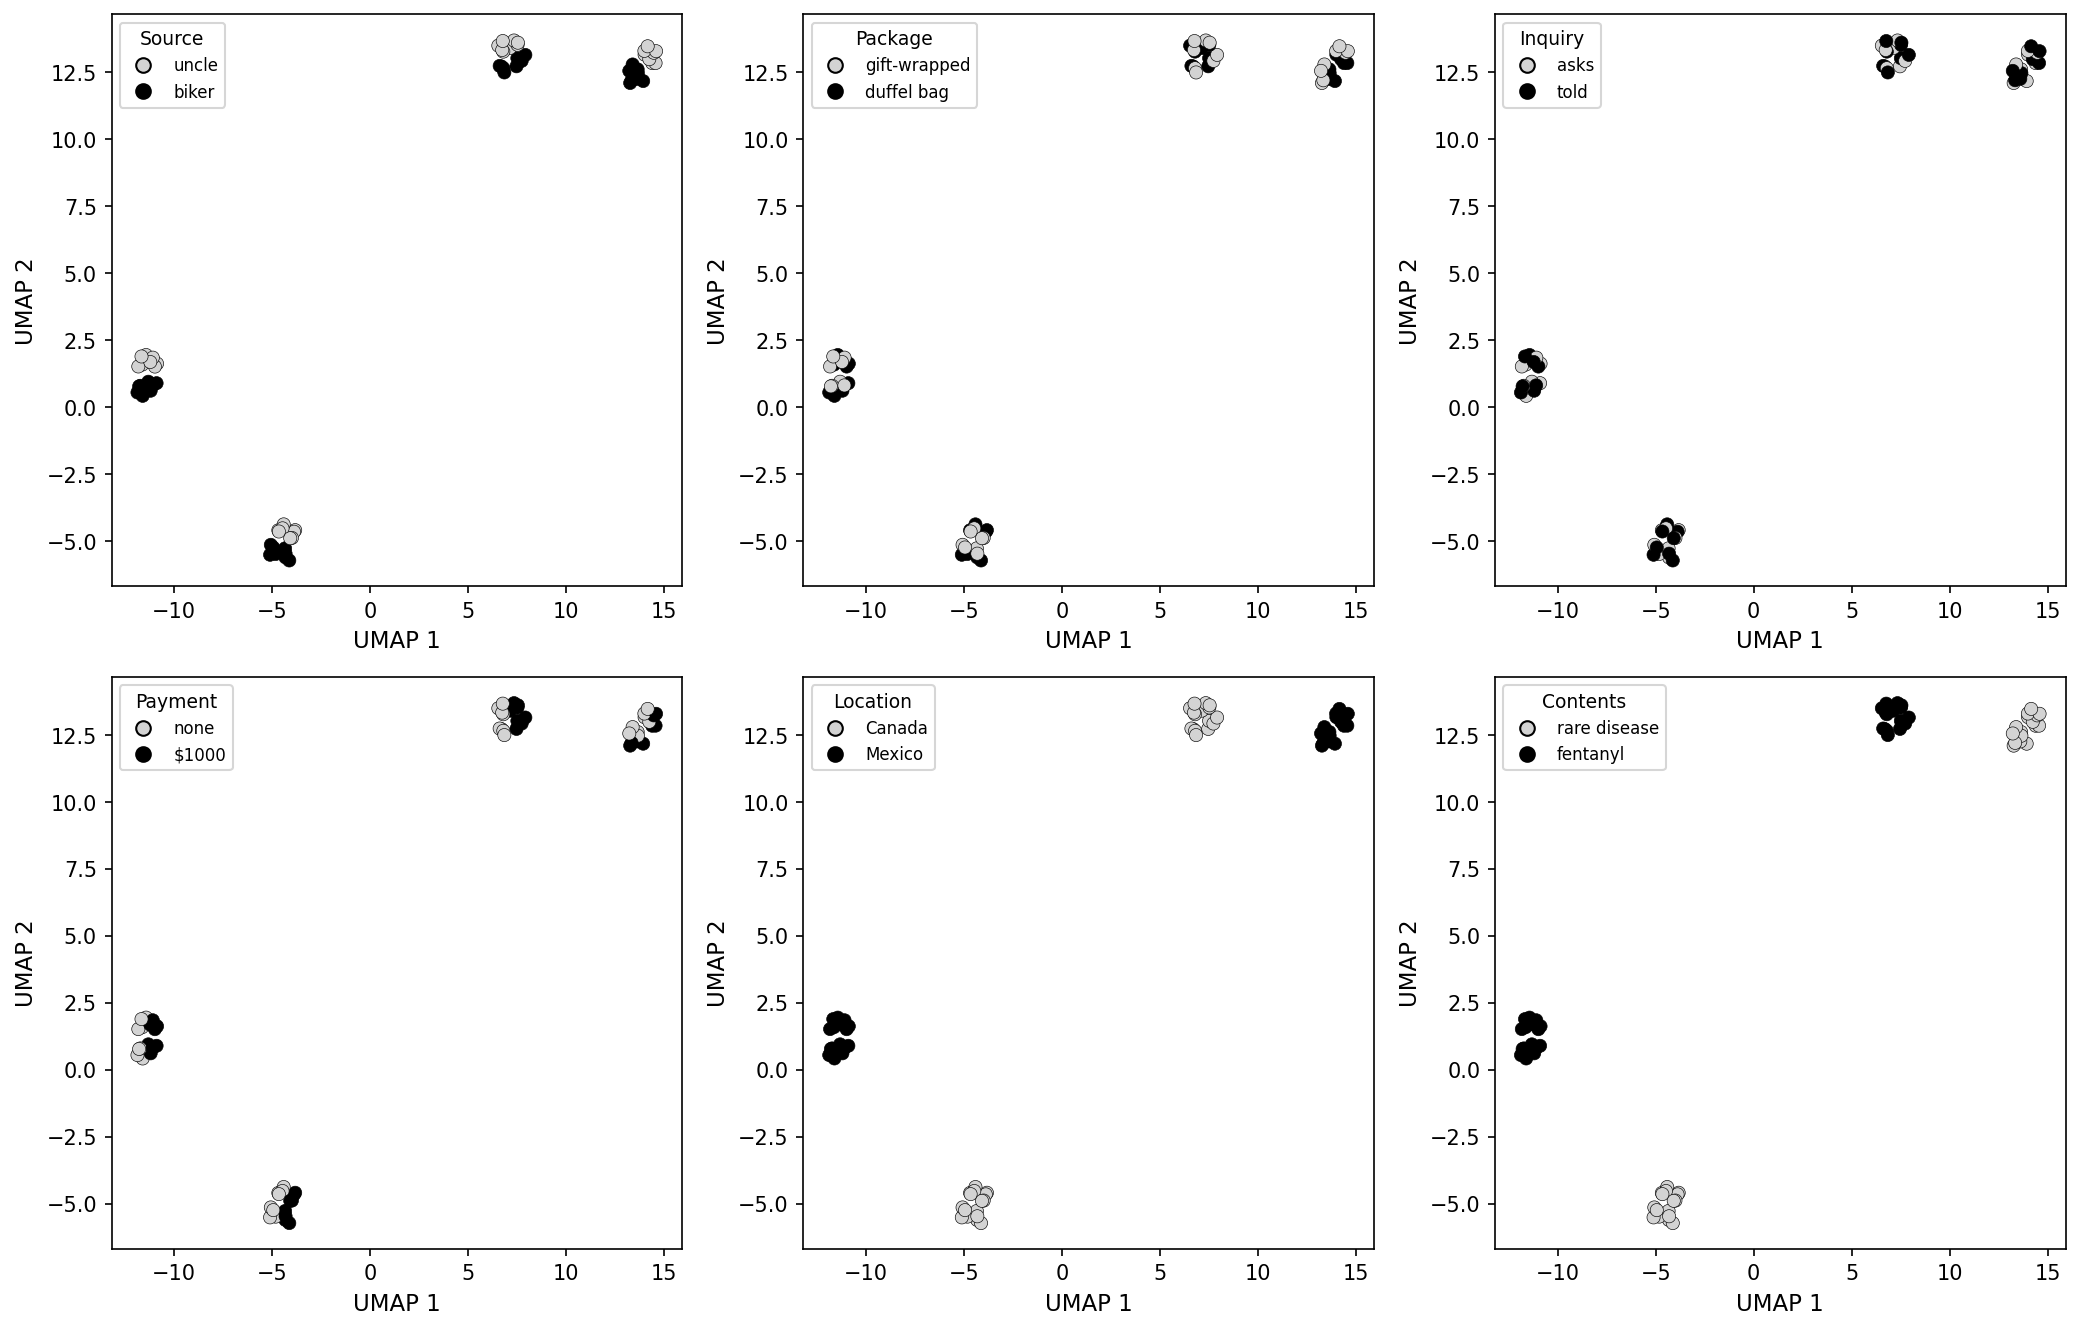

Saved: fig_umap_by_feature.pdf


In [9]:
# ── UMAP panels for each of the 6 features ──
# Each subplot colors the same UMAP projection by a different binary feature,
# showing which features create the most visible separation in embedding space.

feature_bin_cols = ['source_bin', 'package_bin', 'inquiry_bin',
                    'payment_bin', 'location_bin', 'contents_bin']
feature_labels_short = ['Source', 'Package', 'Inquiry', 'Payment', 'Location', 'Contents']
level_labels = [('uncle', 'biker'), ('gift-wrapped', 'duffel bag'),
                ('asks', 'told'), ('none', '$1000'),
                ('Canada', 'Mexico'), ('rare disease', 'fentanyl')]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for i, (col, label, levels) in enumerate(zip(feature_bin_cols, feature_labels_short, level_labels)):
    ax = axes[i]
    colors = ['lightgrey' if v == 0 else 'black' for v in vignette_stats[col]]
    ax.scatter(vignette_stats['umap_x'], vignette_stats['umap_y'],
               c=colors, s=40, edgecolors='black', linewidth=0.3)
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgrey',
               markersize=7, label=levels[0], markeredgecolor='black'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black',
               markersize=7, label=levels[1], markeredgecolor='black'),
    ]
    ax.legend(handles=legend_elements, loc='best', title=label, fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.savefig('fig_umap_by_feature.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_umap_by_feature.pdf")

## 5. Random Forest Classification

We train two Random Forest models to predict the 4-level culpability judgment:

1. **Features-only model** — Uses only the 6 binary vignette features as predictors.
   This is the clean causal test: can objective stimulus properties alone predict
   mental state classification? This avoids the circularity of including a
   participant's own subjective rating as a predictor of their own judgment.

2. **Features + risk slider model** — Adds the continuous risk slider as a 7th
   predictor. This demonstrates that participants' subjective risk perception is
   the proximal driver of their judgments, but should be interpreted as descriptive
   (showing the cognitive process) rather than causal (since the slider is itself
   a participant response).

Both use 10-fold stratified cross-validation with balanced class weights.

In [10]:
# ── Feature columns ──
FEATURE_COLS_NO_SLIDER = ['source_bin', 'package_bin', 'inquiry_bin',
                          'payment_bin', 'location_bin', 'contents_bin']
FEATURE_COLS = ['slider_value'] + FEATURE_COLS_NO_SLIDER

FEATURE_LABELS_NO_SLIDER = ['Source (biker)', 'Package (duffel)', 'Inquiry (told)',
                            'Payment ($1000)', 'Location (Mexico)', 'Contents (fentanyl)']
FEATURE_LABELS = ['Risk Slider'] + FEATURE_LABELS_NO_SLIDER

LABEL_MAP = dict(zip(FEATURE_COLS, FEATURE_LABELS))
JUDGMENT_ORDER = ['Blamelessness', 'Negligence', 'Recklessness', 'Knowledge']

# ── Prepare feature matrices and target ──
X_full = d[FEATURE_COLS].values           # 7 predictors (slider + 6 features)
X_feat = d[FEATURE_COLS_NO_SLIDER].values  # 6 predictors (features only)
y = d['culpability'].values                # 1, 2, 3, 4

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

# ── Model A: Features only (primary — no circularity) ──
rf_feat = RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=5,
    class_weight='balanced', random_state=SEED, n_jobs=-1
)
y_pred_feat = cross_val_predict(rf_feat, X_feat, y, cv=cv)
cv_scores_feat = cross_val_score(rf_feat, X_feat, y, cv=cv, scoring='accuracy')

print("═" * 60)
print("MODEL A: Features only (6 binary vignette features)")
print("═" * 60)
print(f"10-fold CV accuracy: {cv_scores_feat.mean():.3f} ± {cv_scores_feat.std():.3f}")
print(f"Cohen's κ: {cohen_kappa_score(y, y_pred_feat):.3f}")
print(f"  Chance: {1/4:.3f} (uniform) or {pd.Series(y).value_counts(normalize=True).max():.3f} (majority)")
print()
print(classification_report(y, y_pred_feat, target_names=JUDGMENT_ORDER))

# ── Model B: Features + risk slider (descriptive — includes participant response) ──
rf_full_model = RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=5,
    class_weight='balanced', random_state=SEED, n_jobs=-1
)
y_pred_full = cross_val_predict(rf_full_model, X_full, y, cv=cv)
cv_scores_full = cross_val_score(rf_full_model, X_full, y, cv=cv, scoring='accuracy')

print()
print("═" * 60)
print("MODEL B: Features + risk slider (7 predictors)")
print("═" * 60)
print(f"10-fold CV accuracy: {cv_scores_full.mean():.3f} ± {cv_scores_full.std():.3f}")
print(f"Cohen's κ: {cohen_kappa_score(y, y_pred_full):.3f}")
print()
print(classification_report(y, y_pred_full, target_names=JUDGMENT_ORDER))

# ── Comparison ──
print()
print("═" * 60)
print("COMPARISON")
print("═" * 60)
t_ab, p_ab = stats.ttest_rel(cv_scores_full, cv_scores_feat)
print(f"  Features only:     {cv_scores_feat.mean():.3f} ± {cv_scores_feat.std():.3f}")
print(f"  Features + slider: {cv_scores_full.mean():.3f} ± {cv_scores_full.std():.3f}")
print(f"  Improvement: t = {t_ab:.2f}, p = {p_ab:.4f}")
print(f"  The risk slider adds substantial predictive power, confirming it captures")
print(f"  judgment-relevant variance beyond objective stimulus features alone.")

════════════════════════════════════════════════════════════
MODEL A: Features only (6 binary vignette features)
════════════════════════════════════════════════════════════
10-fold CV accuracy: 0.307 ± 0.035
Cohen's κ: 0.074
  Chance: 0.250 (uniform) or 0.426 (majority)

               precision    recall  f1-score   support

Blamelessness       0.26      0.46      0.33       177
   Negligence       0.46      0.23      0.31       452
 Recklessness       0.34      0.41      0.37       286
    Knowledge       0.12      0.15      0.13       145

     accuracy                           0.31      1060
    macro avg       0.30      0.31      0.29      1060
 weighted avg       0.35      0.31      0.31      1060


════════════════════════════════════════════════════════════
MODEL B: Features + risk slider (7 predictors)
════════════════════════════════════════════════════════════
10-fold CV accuracy: 0.473 ± 0.029
Cohen's κ: 0.254

               precision    recall  f1-score   support

Blame

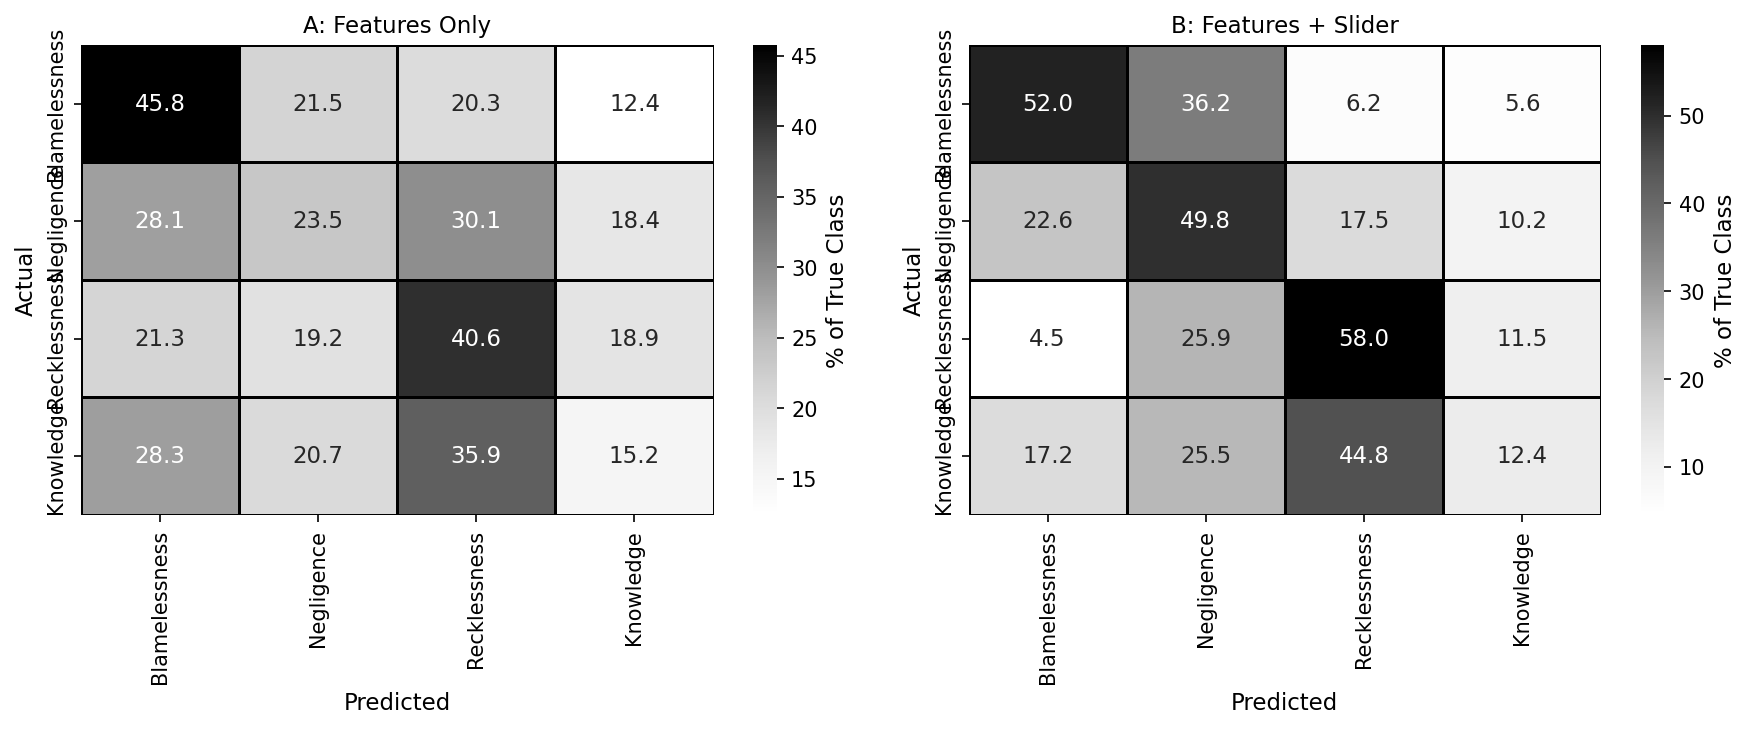

Saved: fig_rf_confusion_matrix.pdf


In [11]:
# ── Confusion matrices for both models ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_feat, 'A: Features Only'),
    (axes[1], y_pred_full, 'B: Features + Slider')
]:
    cm = confusion_matrix(y, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Greys',
                xticklabels=JUDGMENT_ORDER, yticklabels=JUDGMENT_ORDER,
                cbar_kws={'label': '% of True Class'}, linewidths=0.5,
                linecolor='black', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('fig_rf_confusion_matrix.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_rf_confusion_matrix.pdf")

## 6. SHAP Feature Importance

We compute SHAP values for both Random Forest models:

1. **Features-only SHAP** — Shows which objective vignette features drive
   classification without the confound of the risk slider.
2. **Full-model SHAP** — Shows the dominant role of subjective risk perception.

For both, we use TreeExplainer (exact for tree-based models) and produce:
- Global beeswarm/bar plots
- Per-class importance heatmaps
- Dependence and interaction plots

In [12]:
# ── Fit both RF models on full data for SHAP ──
rf_feat_full = RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=5,
    class_weight='balanced', random_state=SEED, n_jobs=-1
)
rf_feat_full.fit(X_feat, y)

rf_all_full = RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=5,
    class_weight='balanced', random_state=SEED, n_jobs=-1
)
rf_all_full.fit(X_full, y)

# ── SHAP for features-only model (primary) ──
explainer_feat = shap.TreeExplainer(rf_feat_full)
shap_values_feat = explainer_feat.shap_values(X_feat)
X_display_feat = pd.DataFrame(X_feat, columns=FEATURE_LABELS_NO_SLIDER)

if isinstance(shap_values_feat, list):
    shap_values_feat = np.array(shap_values_feat).transpose(1, 2, 0)
    print("Features-only: converted list format → 3D array")
print(f"Features-only SHAP shape: {shap_values_feat.shape}")

# ── SHAP for full model (secondary) ──
explainer_full = shap.TreeExplainer(rf_all_full)
shap_values_full = explainer_full.shap_values(X_full)
X_display_full = pd.DataFrame(X_full, columns=FEATURE_LABELS)

if isinstance(shap_values_full, list):
    shap_values_full = np.array(shap_values_full).transpose(1, 2, 0)
    print("Full model: converted list format → 3D array")
print(f"Full model SHAP shape: {shap_values_full.shape}")

# Set defaults to features-only for primary reporting
shap_values = shap_values_feat
X_display = X_display_feat
rf_full = rf_feat_full
explainer = explainer_feat
X = X_feat
N_CLASSES = shap_values.shape[2]

Features-only SHAP shape: (1060, 6, 4)
Full model SHAP shape: (1060, 7, 4)


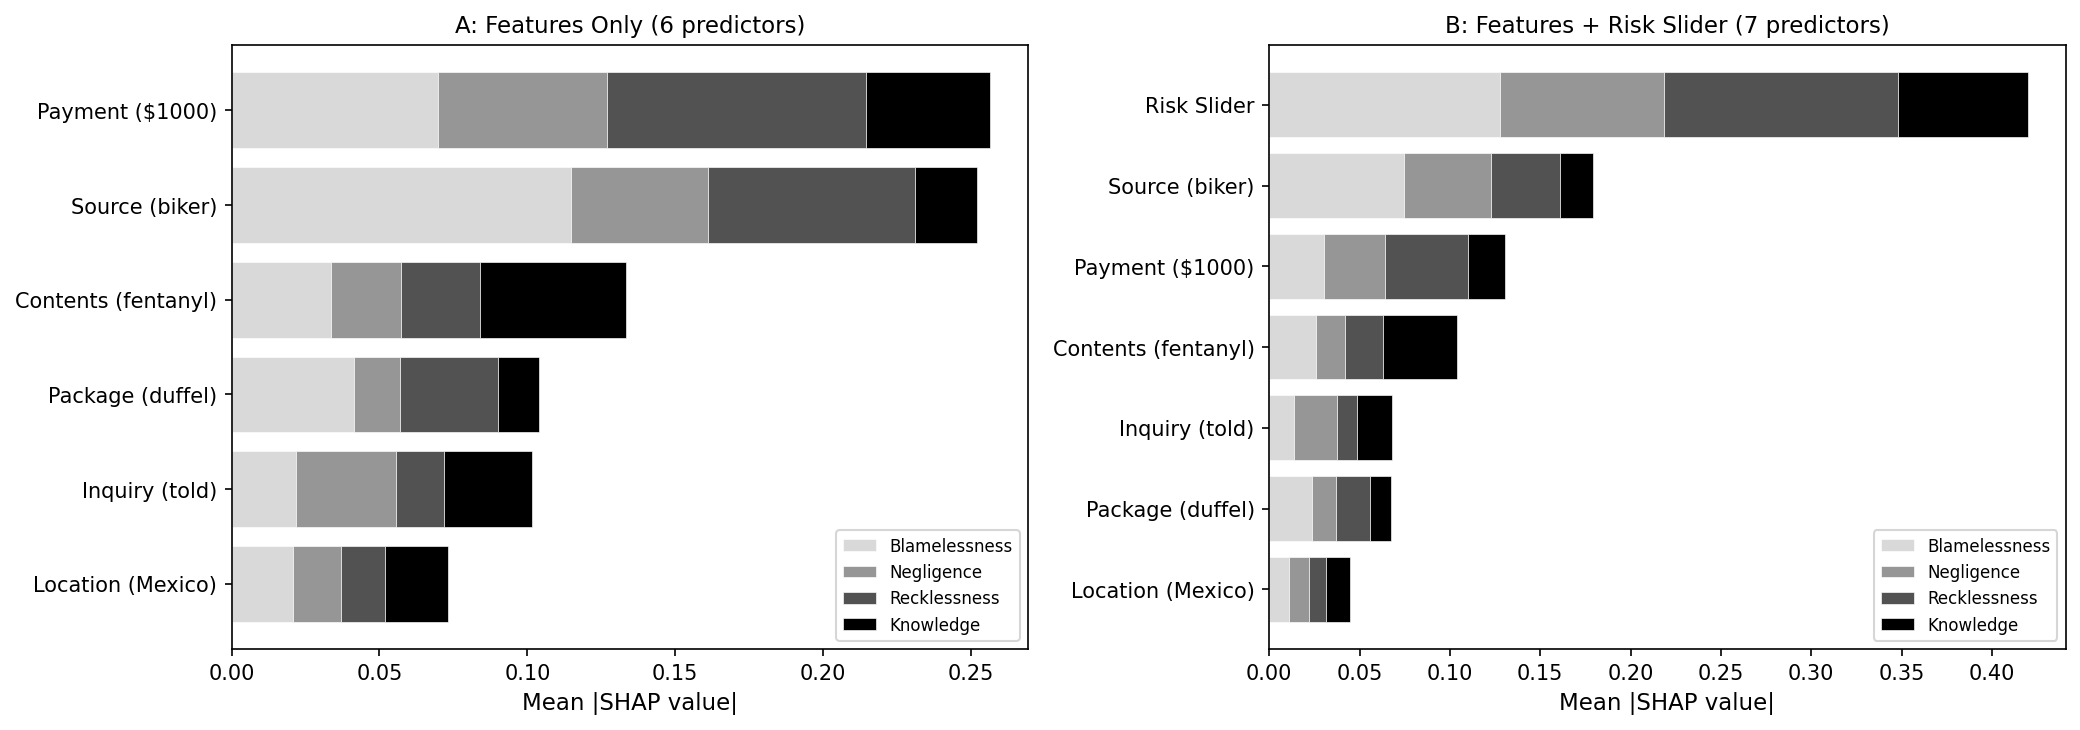

Saved: fig_shap_bar_global.pdf


In [13]:
# ── Global SHAP bar plots: computed manually for full control ──
# shap.summary_plot manages its own figure internally and ignores pre-created
# axes, so we compute mean |SHAP| per class ourselves and plot with matplotlib.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Panel A: Features only ──
mean_shap_feat = np.mean(np.abs(shap_values_feat), axis=0)  # (n_features, n_classes)
ax = axes[0]
bottom = np.zeros(mean_shap_feat.shape[0])
gray_shades = ['#d9d9d9', '#969696', '#525252', '#000000']
sorted_idx = np.argsort(mean_shap_feat.mean(axis=1))  # sort by overall importance

for c in range(mean_shap_feat.shape[1]):
    ax.barh(np.arange(len(sorted_idx)), mean_shap_feat[sorted_idx, c],
            left=bottom[sorted_idx], color=gray_shades[c],
            edgecolor='white', linewidth=0.3, label=JUDGMENT_ORDER[c])
    bottom += mean_shap_feat[:, c]

ax.set_yticks(np.arange(len(sorted_idx)))
ax.set_yticklabels([FEATURE_LABELS_NO_SLIDER[i] for i in sorted_idx])
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('A: Features Only (6 predictors)', fontsize=11)
ax.legend(fontsize=8, loc='lower right')

# ── Panel B: Features + slider ──
mean_shap_full = np.mean(np.abs(shap_values_full), axis=0)  # (n_features, n_classes)
ax = axes[1]
bottom = np.zeros(mean_shap_full.shape[0])
sorted_idx = np.argsort(mean_shap_full.mean(axis=1))

for c in range(mean_shap_full.shape[1]):
    ax.barh(np.arange(len(sorted_idx)), mean_shap_full[sorted_idx, c],
            left=bottom[sorted_idx], color=gray_shades[c],
            edgecolor='white', linewidth=0.3, label=JUDGMENT_ORDER[c])
    bottom += mean_shap_full[:, c]

ax.set_yticks(np.arange(len(sorted_idx)))
ax.set_yticklabels([FEATURE_LABELS[i] for i in sorted_idx])
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('B: Features + Risk Slider (7 predictors)', fontsize=11)
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('fig_shap_bar_global.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_shap_bar_global.pdf")

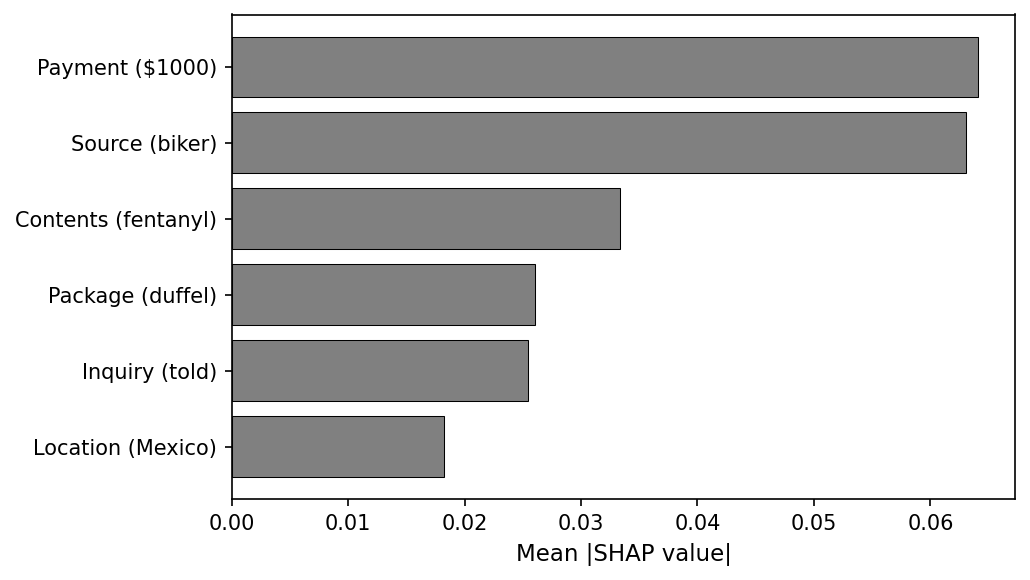

Saved: fig_shap_importance_bar.pdf


In [14]:
# ── Mean |SHAP| bar plot: features-only model ──
mean_abs_shap = np.mean(np.abs(shap_values_feat), axis=(0, 2))
importance_df = pd.DataFrame({
    'Feature': FEATURE_LABELS_NO_SLIDER,
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance_df['Feature'], importance_df['Mean |SHAP|'],
        color='grey', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Mean |SHAP value|')

plt.tight_layout()
plt.savefig('fig_shap_importance_bar.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_shap_importance_bar.pdf")

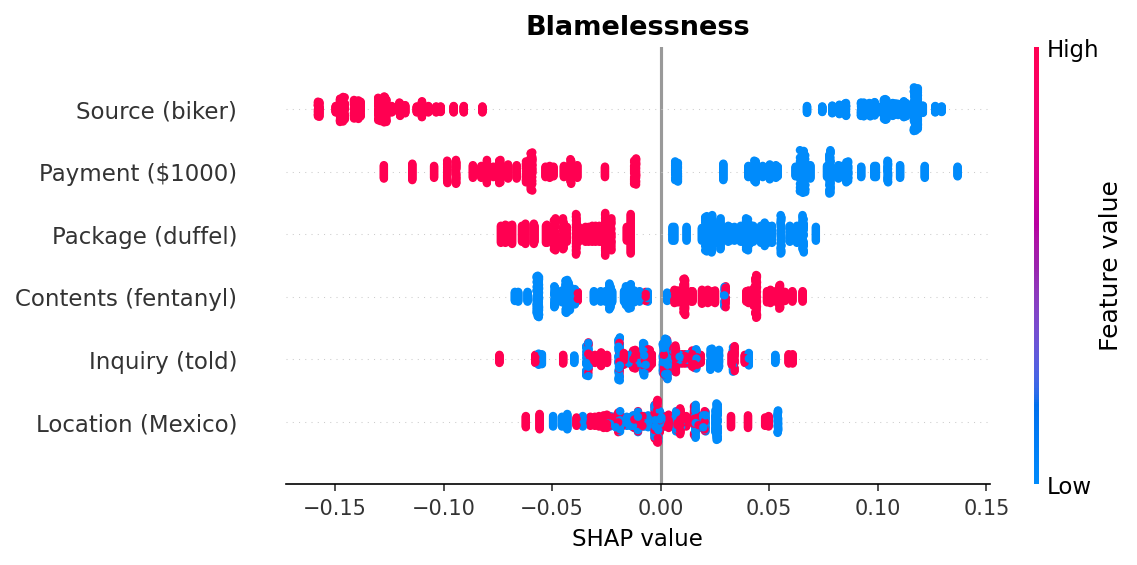

Saved: fig_shap_blamelessness.pdf



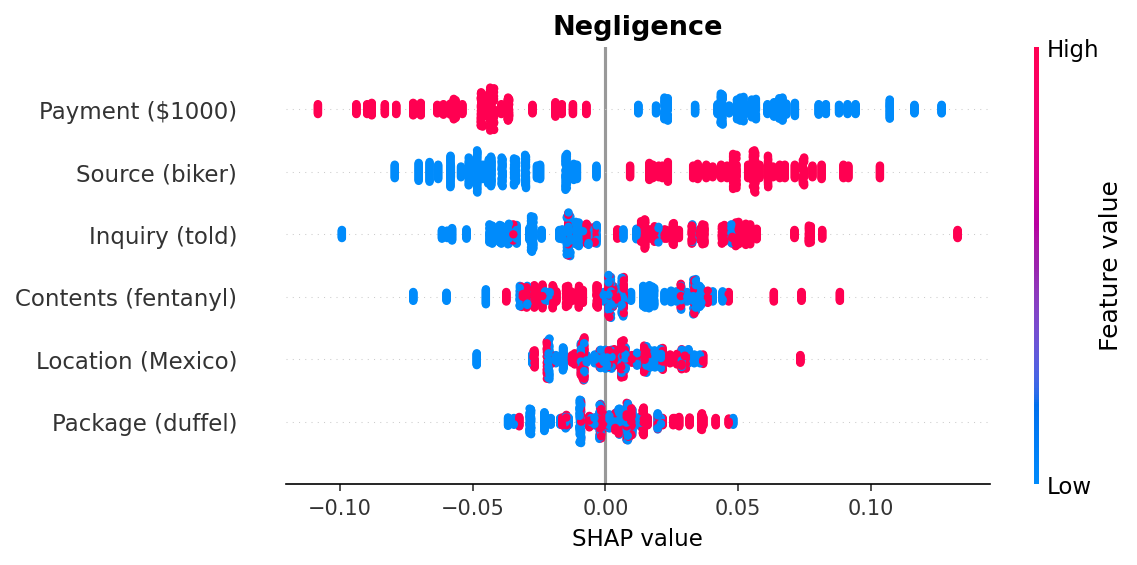

Saved: fig_shap_negligence.pdf



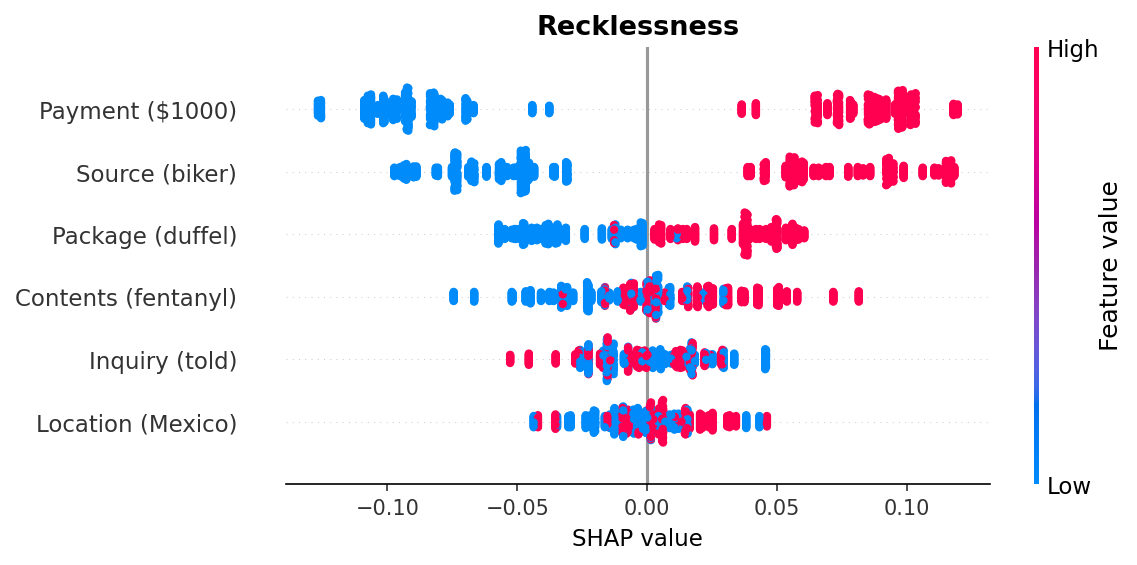

Saved: fig_shap_recklessness.pdf



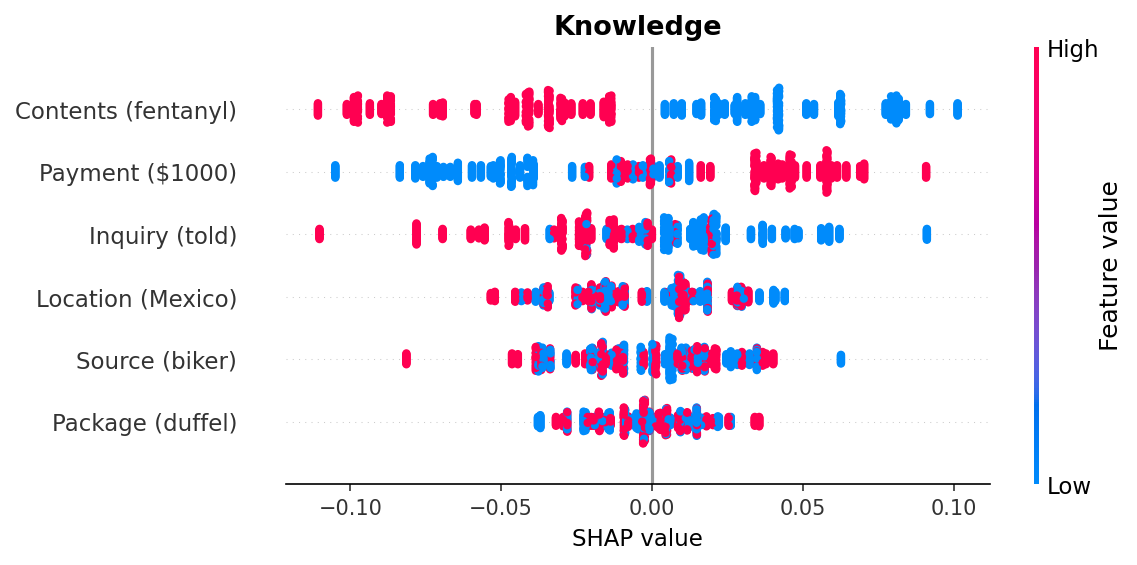

Saved: fig_shap_knowledge.pdf



In [15]:
# ── Per-class SHAP beeswarm plots (features-only model) ──
# Each class gets its own figure to avoid SHAP's internal figure management
# conflicting with subplot layouts. Saved as separate PDFs that can be
# composed into a multi-panel figure in the manuscript.

for i, label in enumerate(JUDGMENT_ORDER):
    fig, ax = plt.subplots(figsize=(7, 4))
    shap.summary_plot(shap_values_feat[:, :, i], X_display_feat,
                      plot_type='dot', show=False, max_display=6,
                      color_bar=True)
    ax.set_title(label, fontsize=13, fontweight='bold')
    ax.set_xlabel('SHAP value', fontsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.tick_params(axis='x', labelsize=10)
    plt.tight_layout()
    fname = f'fig_shap_{label.lower()}.pdf'
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}")
    print()

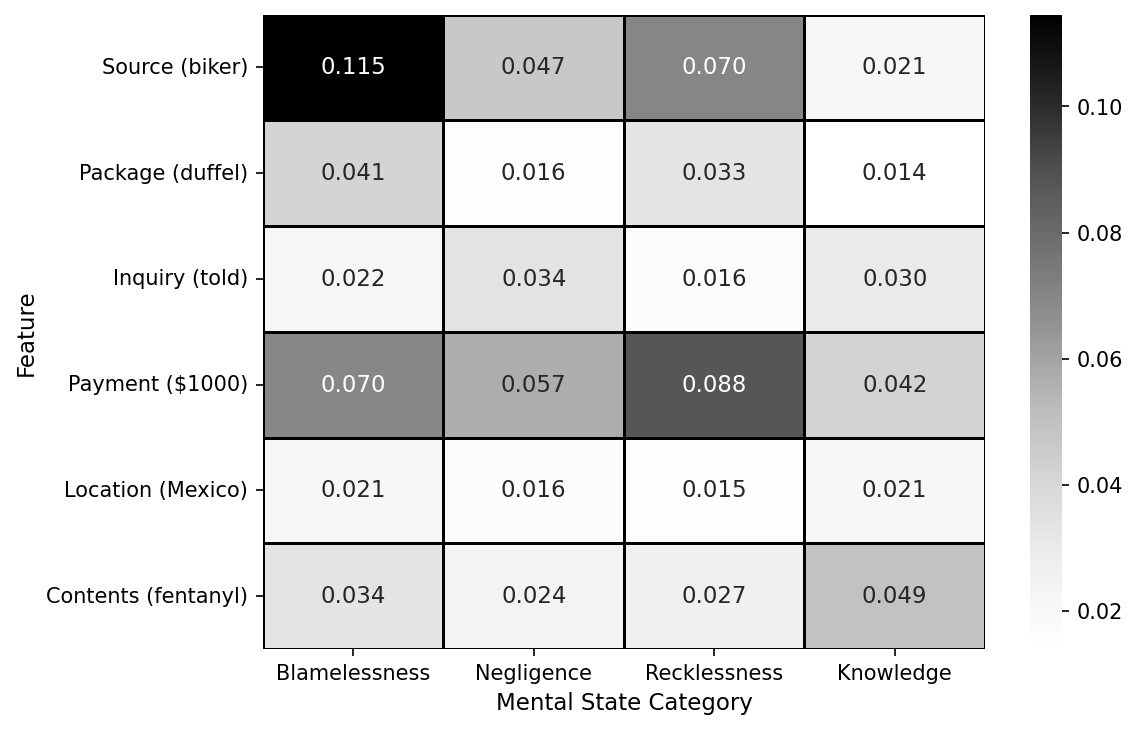

Saved: fig_shap_class_heatmap.pdf


In [16]:
# ── Per-class mean |SHAP| heatmap (features-only model) ──
class_importance = np.mean(np.abs(shap_values_feat), axis=0)  # (n_features, n_classes)
heatmap_df = pd.DataFrame(class_importance,
                           index=FEATURE_LABELS_NO_SLIDER,
                           columns=JUDGMENT_ORDER)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heatmap_df, annot=True, fmt='.3f', cmap='Greys',
            linewidths=0.5, linecolor='black', ax=ax)
ax.set_ylabel('Feature')
ax.set_xlabel('Mental State Category')

plt.tight_layout()
plt.savefig('fig_shap_class_heatmap.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_shap_class_heatmap.pdf")

## 7. SHAP Dependence and Interaction Effects

Dependence plots show how the SHAP value for a given feature varies as a function
of that feature's actual value. For binary features, this produces two clusters of
points (0 vs 1). For the continuous risk slider, it shows the shape of the
feature-response curve. Color is used to show the strongest interacting feature
(selected automatically by SHAP).

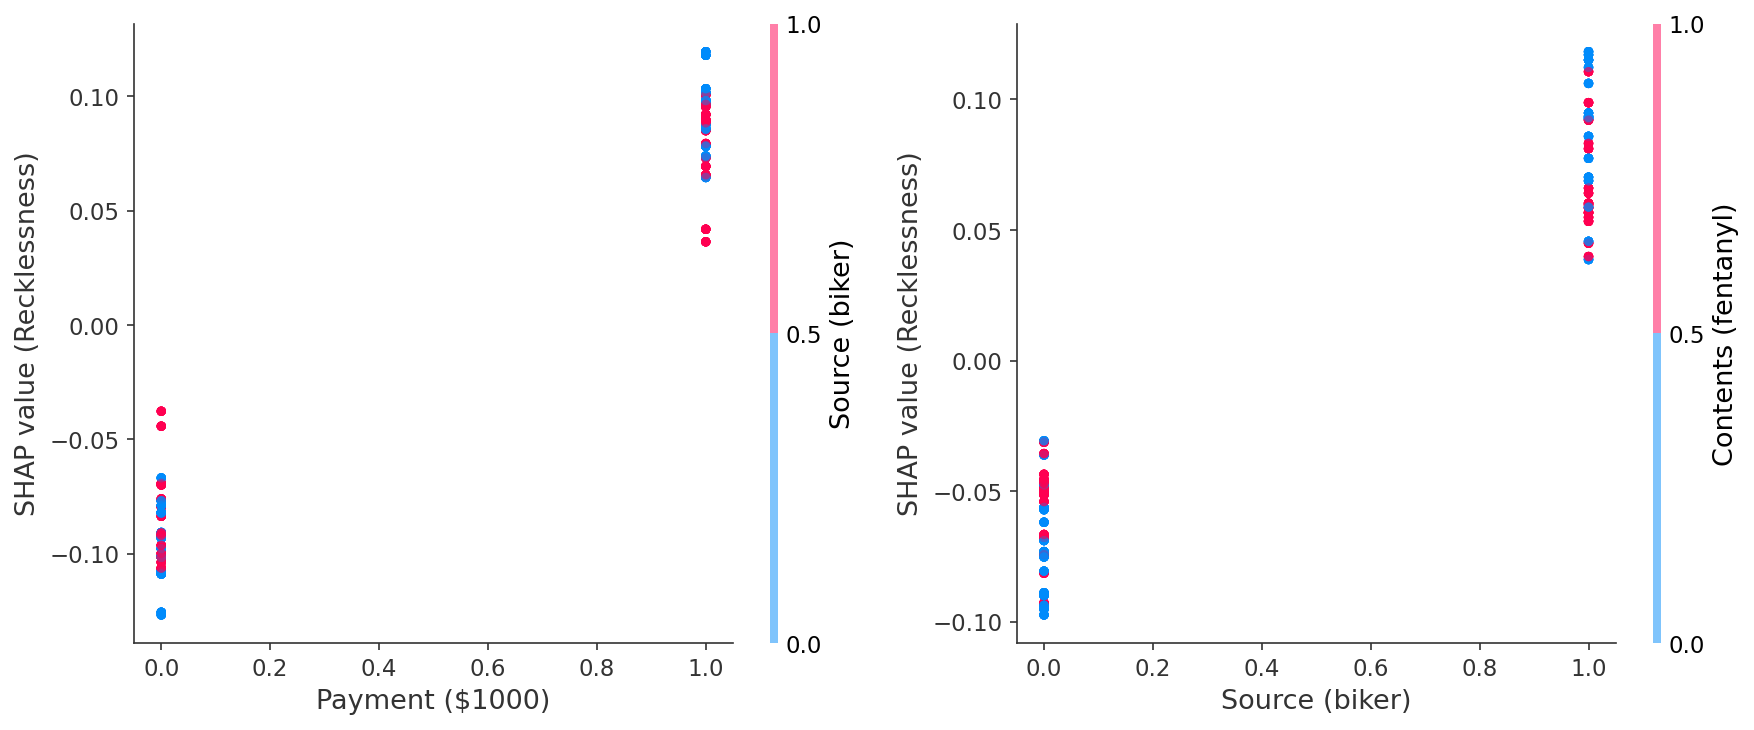

Saved: fig_shap_dependence.pdf


In [17]:
# ── SHAP dependence plots for the two most important features ──
# From the features-only model (no slider), payment and source are the top two.
# We plot their dependence for the Recklessness class (index 2).

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Payment dependence (Recklessness class)
ax = axes[0]
shap.dependence_plot('Payment ($1000)', shap_values_feat[:, :, 2], X_display_feat,
                     interaction_index='auto', ax=ax, show=False,
                     dot_size=20, alpha=0.5)
ax.set_ylabel('SHAP value (Recklessness)')

# Source dependence (Recklessness class)
ax = axes[1]
shap.dependence_plot('Source (biker)', shap_values_feat[:, :, 2], X_display_feat,
                     interaction_index='auto', ax=ax, show=False,
                     dot_size=20, alpha=0.5)
ax.set_ylabel('SHAP value (Recklessness)')

plt.tight_layout()
plt.savefig('fig_shap_dependence.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_shap_dependence.pdf")

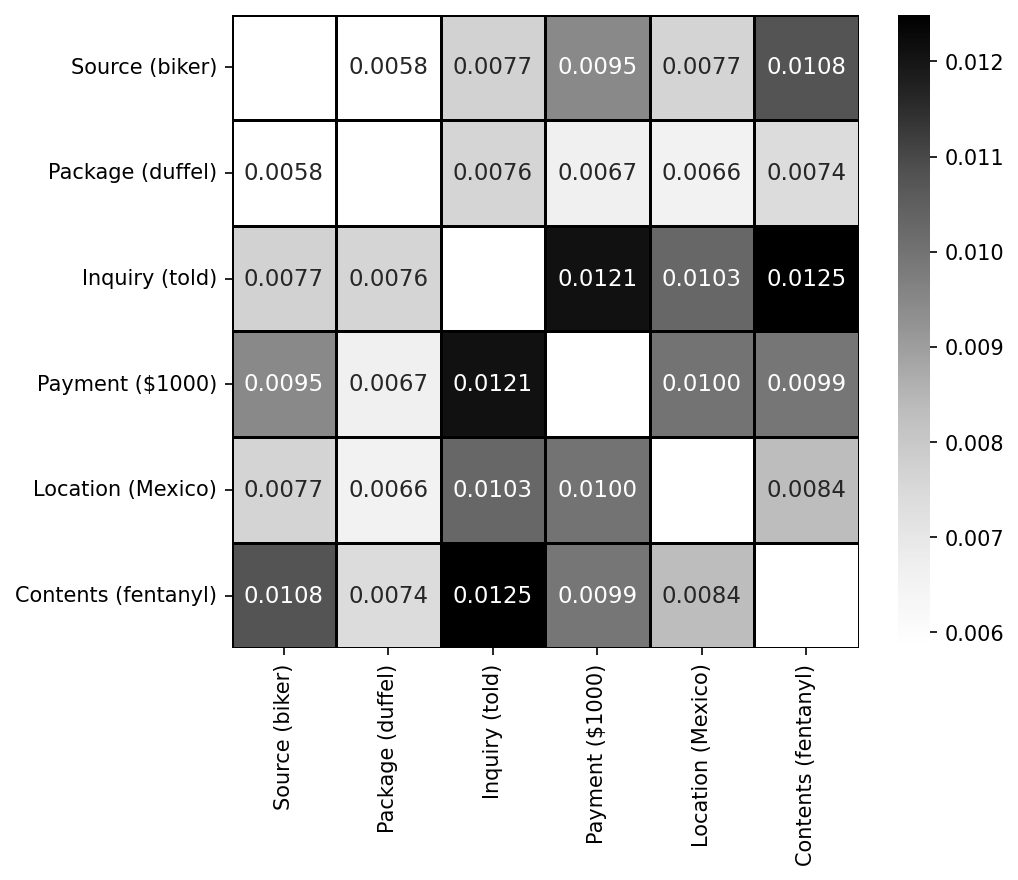

Saved: fig_shap_interactions.pdf


In [18]:
# ── SHAP interaction values (features-only model) ──
n_interaction_samples = min(200, len(X_feat))
X_sample = X_feat[:n_interaction_samples]

shap_interaction = explainer_feat.shap_interaction_values(X_sample)

if isinstance(shap_interaction, list):
    shap_interaction = np.array(shap_interaction)
    shap_interaction = shap_interaction.transpose(1, 2, 3, 0)

mean_interactions = (np.mean(np.abs(shap_interaction), axis=(0, 3))
                     if shap_interaction.ndim == 4
                     else np.mean(np.abs(shap_interaction), axis=0))

np.fill_diagonal(mean_interactions, 0)

interaction_df = pd.DataFrame(mean_interactions,
                               index=FEATURE_LABELS_NO_SLIDER,
                               columns=FEATURE_LABELS_NO_SLIDER)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(interaction_df, annot=True, fmt='.4f', cmap='Greys',
            linewidths=0.5, linecolor='black', ax=ax,
            mask=np.eye(len(FEATURE_LABELS_NO_SLIDER), dtype=bool))

plt.tight_layout()
plt.savefig('fig_shap_interactions.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_shap_interactions.pdf")

## 8. Representational Similarity Analysis (RSA)

Do vignettes that are semantically closer in embedding space elicit more similar
culpability judgments? We compute pairwise cosine distances between all unique
vignette embeddings and correlate them with pairwise differences in mean culpability.

We run the RSA three ways to address the concern that templated vignettes with
small word-level changes produce near-identical embeddings in mean-pooling models:

1. **BGE-large full-text** (CLS pooling, contrastive-trained) — primary analysis
2. **MiniLM full-text** (mean pooling) — robustness check
3. **BGE-large clause-level** — embed only the text fragments that vary between
   conditions, eliminating the dilution from shared template text

In [19]:
# ── Helper function for RSA ──
def compute_rsa(embedding_dict, vignette_stats_df, label=""):
    """Compute RSA between embedding distances and judgment distances."""
    emb_matrix = np.array([embedding_dict[k] for k in vignette_stats_df['vignette_key']])
    cos_dists = squareform(pdist(emb_matrix, metric='cosine'))
    culp_vals = vignette_stats_df['mean_culp'].values
    culp_diffs = squareform(pdist(culp_vals.reshape(-1, 1), metric='cityblock'))
    triu = np.triu_indices(len(cos_dists), k=1)
    cos_vec = cos_dists[triu]
    culp_vec = culp_diffs[triu]
    rho, p_val = stats.spearmanr(cos_vec, culp_vec)
    print(f"  {label}: ρ = {rho:.3f}, p = {p_val:.4f} (N pairs = {len(cos_vec)})")
    return cos_vec, culp_vec, rho, p_val

# ── RSA with both models ──
print("═" * 60)
print("RSA: Full-Text Embeddings")
print("═" * 60)
cos_vec_bge, culp_vec, rho_bge, p_bge = compute_rsa(
    key_to_embedding_bge, vignette_stats, "BGE-large (primary)")
cos_vec_mini, _, rho_mini, p_mini = compute_rsa(
    key_to_embedding_mini, vignette_stats, "MiniLM (robustness)")

# ── Clause-level RSA ──
print()
print("═" * 60)
print("RSA: Clause-Level Embeddings (varying text only)")
print("═" * 60)

def extract_varying_clauses(row):
    """Build a string of just the feature-specific text for a vignette."""
    parts = []
    parts.append("Mexico" if row['location_bin'] == 1 else "Canada")
    parts.append("a biker" if row['source_bin'] == 1 else "his uncle")
    parts.append("a large duffel bag" if row['package_bin'] == 1 else "a gift-wrapped package")
    parts.append("His uncle tells him it is just coffee" if row['inquiry_bin'] == 1
                 else "He asks what is inside and his uncle says it is just coffee")
    parts.append("for one thousand dollars" if row['payment_bin'] == 1
                 else "without asking for payment")
    parts.append("fentanyl, a potent narcotic drug" if row['contents_bin'] == 1
                 else "drugs to treat a rare disease not yet approved in the US")
    return " | ".join(parts)

vignette_stats['clause_text'] = vignette_stats.apply(extract_varying_clauses, axis=1)
clause_texts = vignette_stats['clause_text'].tolist()
clause_embeddings = st_model_bge.encode(clause_texts, normalize_embeddings=True)
key_to_clause_emb = dict(zip(vignette_stats['vignette_key'], clause_embeddings))

cos_vec_clause, _, rho_clause, p_clause = compute_rsa(
    key_to_clause_emb, vignette_stats, "BGE-large clause-level")

print()
print("═" * 60)
print("RSA Summary")
print("═" * 60)
print(f"  BGE full-text:    ρ = {rho_bge:.3f}, p = {p_bge:.4f}")
print(f"  MiniLM full-text: ρ = {rho_mini:.3f}, p = {p_mini:.4f}")
print(f"  BGE clause-level: ρ = {rho_clause:.3f}, p = {p_clause:.4f}")

════════════════════════════════════════════════════════════
RSA: Full-Text Embeddings
════════════════════════════════════════════════════════════
  BGE-large (primary): ρ = 0.077, p = 0.0006 (N pairs = 2016)
  MiniLM (robustness): ρ = 0.019, p = 0.3949 (N pairs = 2016)

════════════════════════════════════════════════════════════
RSA: Clause-Level Embeddings (varying text only)
════════════════════════════════════════════════════════════
  BGE-large clause-level: ρ = 0.129, p = 0.0000 (N pairs = 2016)

════════════════════════════════════════════════════════════
RSA Summary
════════════════════════════════════════════════════════════
  BGE full-text:    ρ = 0.077, p = 0.0006
  MiniLM full-text: ρ = 0.019, p = 0.3949
  BGE clause-level: ρ = 0.129, p = 0.0000


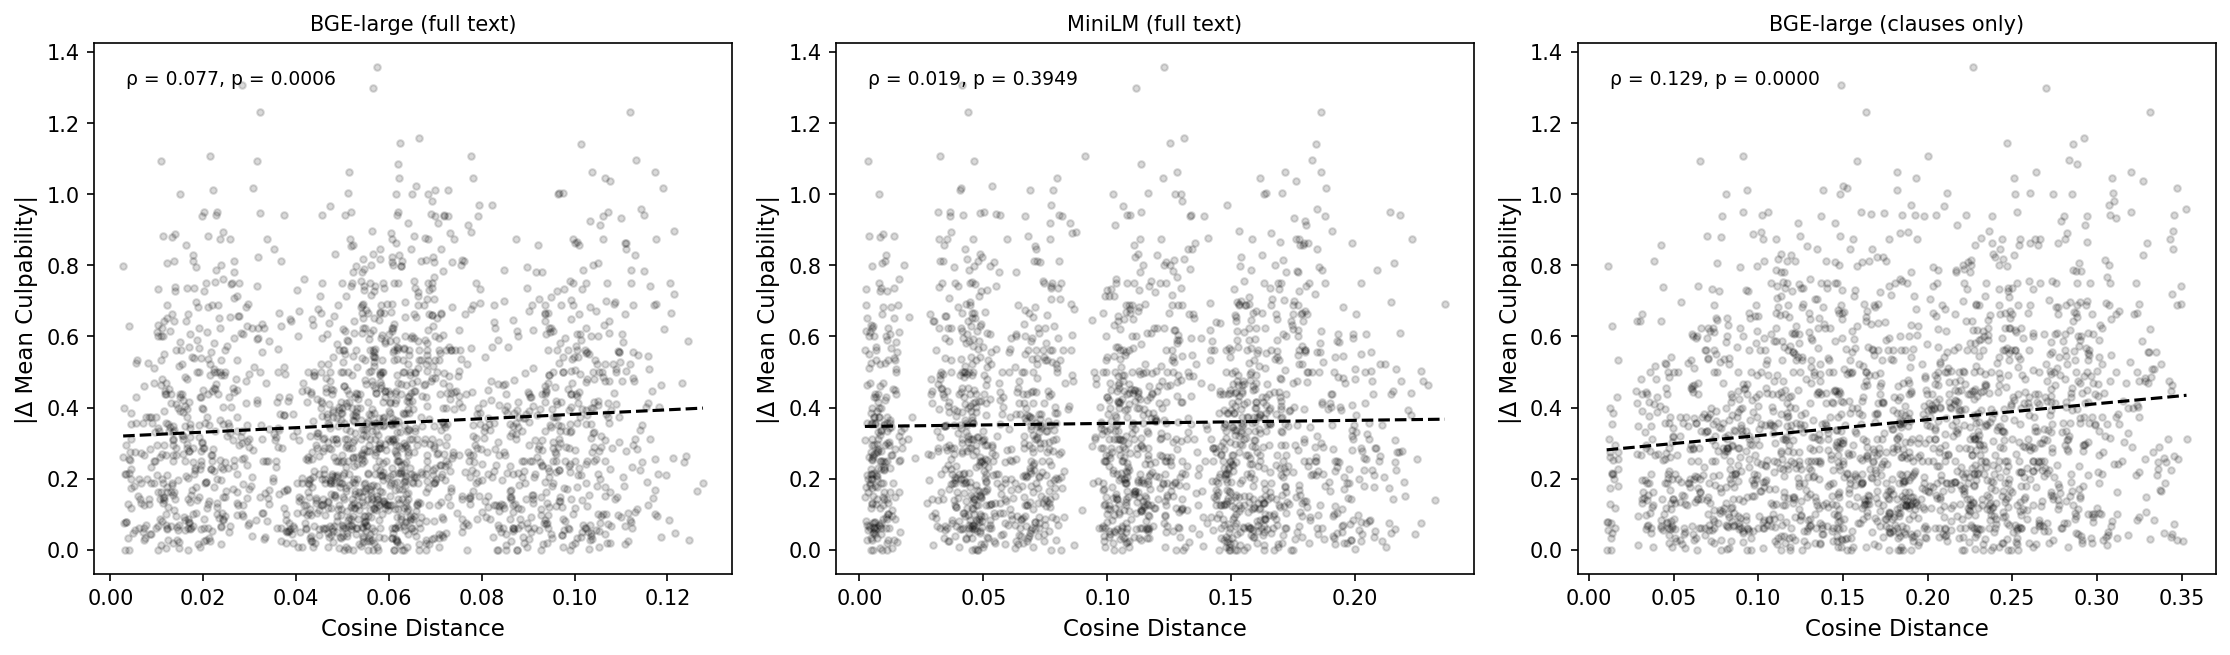

Saved: fig_rsa_scatter.pdf


In [20]:
# ── RSA scatter plots: all three analyses ──
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, cos_vec, rho, p_val, title in [
    (axes[0], cos_vec_bge, rho_bge, p_bge, 'BGE-large (full text)'),
    (axes[1], cos_vec_mini, rho_mini, p_mini, 'MiniLM (full text)'),
    (axes[2], cos_vec_clause, rho_clause, p_clause, 'BGE-large (clauses only)'),
]:
    ax.scatter(cos_vec, culp_vec, alpha=0.15, s=10, color='black')
    z = np.polyfit(cos_vec, culp_vec, 1)
    p_line = np.poly1d(z)
    x_line = np.linspace(cos_vec.min(), cos_vec.max(), 100)
    ax.plot(x_line, p_line(x_line), color='black', linewidth=1.5, linestyle='--')
    ax.set_xlabel('Cosine Distance')
    ax.set_ylabel('|Δ Mean Culpability|')
    ax.annotate(f'ρ = {rho:.3f}, p = {p_val:.4f}',
                xy=(0.05, 0.95), xycoords='axes fraction', fontsize=9, va='top')
    ax.set_title(title, fontsize=10)

plt.tight_layout()
plt.savefig('fig_rsa_scatter.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_rsa_scatter.pdf")

  Source: BGE=0.0127, MiniLM=0.0356 (32 pairs)
  Package: BGE=0.0079, MiniLM=0.0069 (32 pairs)
  Inquiry: BGE=0.0042, MiniLM=0.0054 (32 pairs)
  Payment: BGE=0.0117, MiniLM=0.0035 (32 pairs)
  Location: BGE=0.0443, MiniLM=0.0507 (32 pairs)
  Contents: BGE=0.0380, MiniLM=0.1043 (32 pairs)


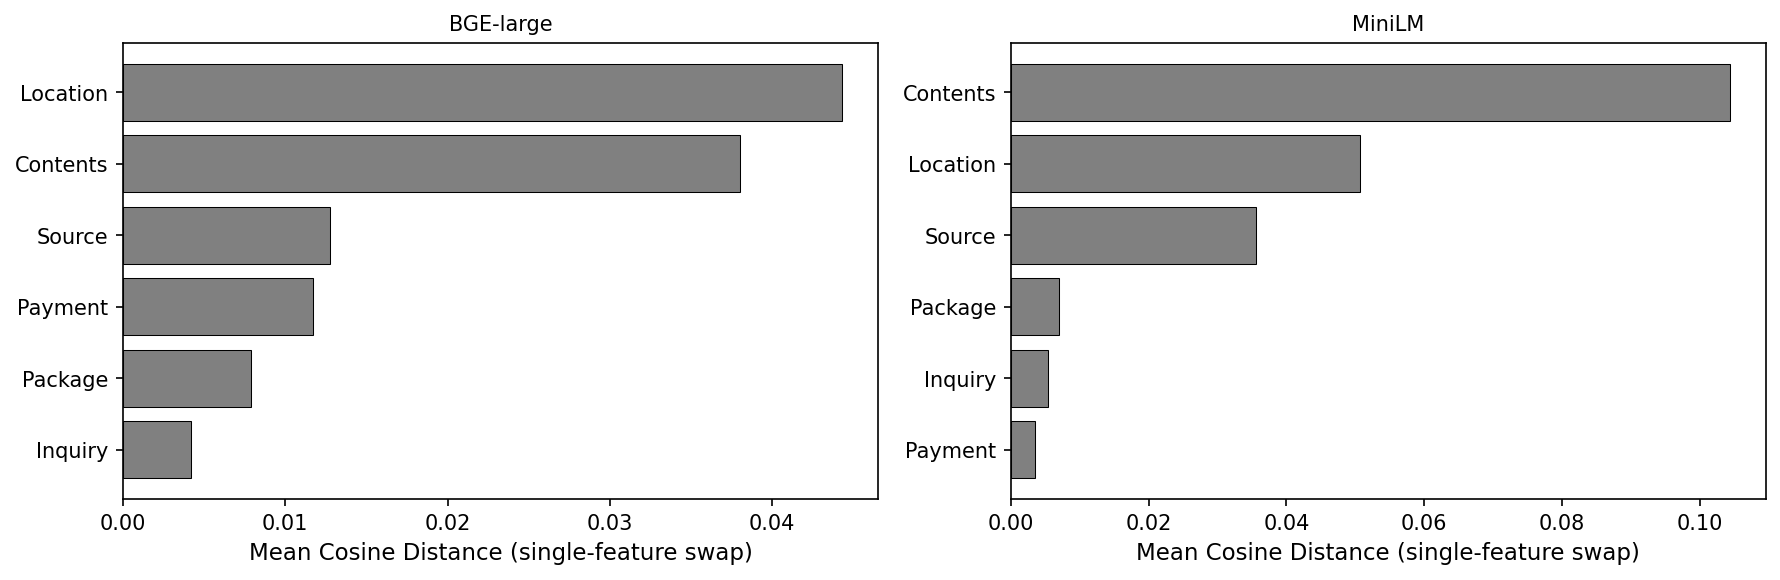

Saved: fig_embedding_feature_distances.pdf


In [21]:
# ── Feature-specific embedding distances ──
# For each binary feature, compute the mean cosine distance between vignettes
# that differ ONLY on that feature (holding all others constant).
# Run for both BGE and MiniLM to show the dilution effect.

bin_cols = ['source_bin', 'package_bin', 'inquiry_bin',
            'payment_bin', 'location_bin', 'contents_bin']
short_labels = ['Source', 'Package', 'Inquiry', 'Payment', 'Location', 'Contents']

# Precompute cosine distance matrices for both models
emb_bge = np.array([key_to_embedding_bge[k] for k in vignette_stats['vignette_key']])
emb_mini = np.array([key_to_embedding_mini[k] for k in vignette_stats['vignette_key']])
cos_mat_bge = squareform(pdist(emb_bge, metric='cosine'))
cos_mat_mini = squareform(pdist(emb_mini, metric='cosine'))

results = []
for col, label in zip(bin_cols, short_labels):
    dists_bge, dists_mini = [], []
    for i in range(len(vignette_stats)):
        for j in range(i + 1, len(vignette_stats)):
            row_i, row_j = vignette_stats.iloc[i], vignette_stats.iloc[j]
            other_cols = [c for c in bin_cols if c != col]
            if all(row_i[c] == row_j[c] for c in other_cols) and row_i[col] != row_j[col]:
                dists_bge.append(cos_mat_bge[i, j])
                dists_mini.append(cos_mat_mini[i, j])
    results.append({
        'Feature': label,
        'BGE dist': np.mean(dists_bge) if dists_bge else 0,
        'MiniLM dist': np.mean(dists_mini) if dists_mini else 0,
        'N pairs': len(dists_bge)
    })
    print(f"  {label}: BGE={np.mean(dists_bge):.4f}, MiniLM={np.mean(dists_mini):.4f} ({len(dists_bge)} pairs)")

fd_df = pd.DataFrame(results).sort_values('BGE dist', ascending=True)

# Side-by-side bar plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], 'BGE dist', 'BGE-large'), (axes[1], 'MiniLM dist', 'MiniLM')]:
    df_sorted = fd_df.sort_values(col, ascending=True)
    ax.barh(df_sorted['Feature'], df_sorted[col], color='grey', edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Mean Cosine Distance (single-feature swap)')
    ax.set_title(title, fontsize=10)

plt.tight_layout()
plt.savefig('fig_embedding_feature_distances.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig_embedding_feature_distances.pdf")

## 9. Free-Text Justification Analysis

Each participant wrote a brief justification after each vignette trial explaining
what contributed to their judgment. If the CSV includes a `justification` column,
we embed these texts and analyze them. If the column is absent or empty, this
section is skipped.

The analyses include:
1. **Embedding and UMAP projection** of justification texts
2. **BERTopic** topic modeling to discover recurring reasoning themes
3. **Text-to-judgment classification** — can a model predict the judgment from the justification alone?

In [22]:
# ── Check whether justification text is available ──
JUSTIFICATION_COL = None
for candidate in ['justification', 'justification_text', 'free_response', 'response_text']:
    if candidate in d.columns:
        non_empty = d[candidate].dropna().astype(str).str.strip().str.len() > 0
        if non_empty.sum() > 10:
            JUSTIFICATION_COL = candidate
            break

if JUSTIFICATION_COL is None:
    print("No justification text column found in the CSV.")
    print("Possible reasons: the preprocessing script may not have extracted it,")
    print("or the column may have a different name.")
    print("Available columns:", list(d.columns))
    print()
    print("SKIPPING Sections 9–10. Re-run after adding justification text to the CSV.")
    HAS_JUSTIFICATIONS = False
else:
    d['justification_clean'] = d[JUSTIFICATION_COL].fillna('').astype(str).str.strip()
    d_just = d[d['justification_clean'].str.len() > 5].copy()
    HAS_JUSTIFICATIONS = True
    print(f"Justification column found: '{JUSTIFICATION_COL}'")
    print(f"Trials with justification text (>5 chars): {len(d_just)} / {len(d)}")
    print(f"Sample: '{d_just['justification_clean'].iloc[0][:120]}...'")

Justification column found: 'justification'
Trials with justification text (>5 chars): 1044 / 1060
Sample: 'How i thought about John...'


Embedding 1044 justifications with BGE-large...


Batches:   0%|          | 0/33 [00:00<?, ?it/s]

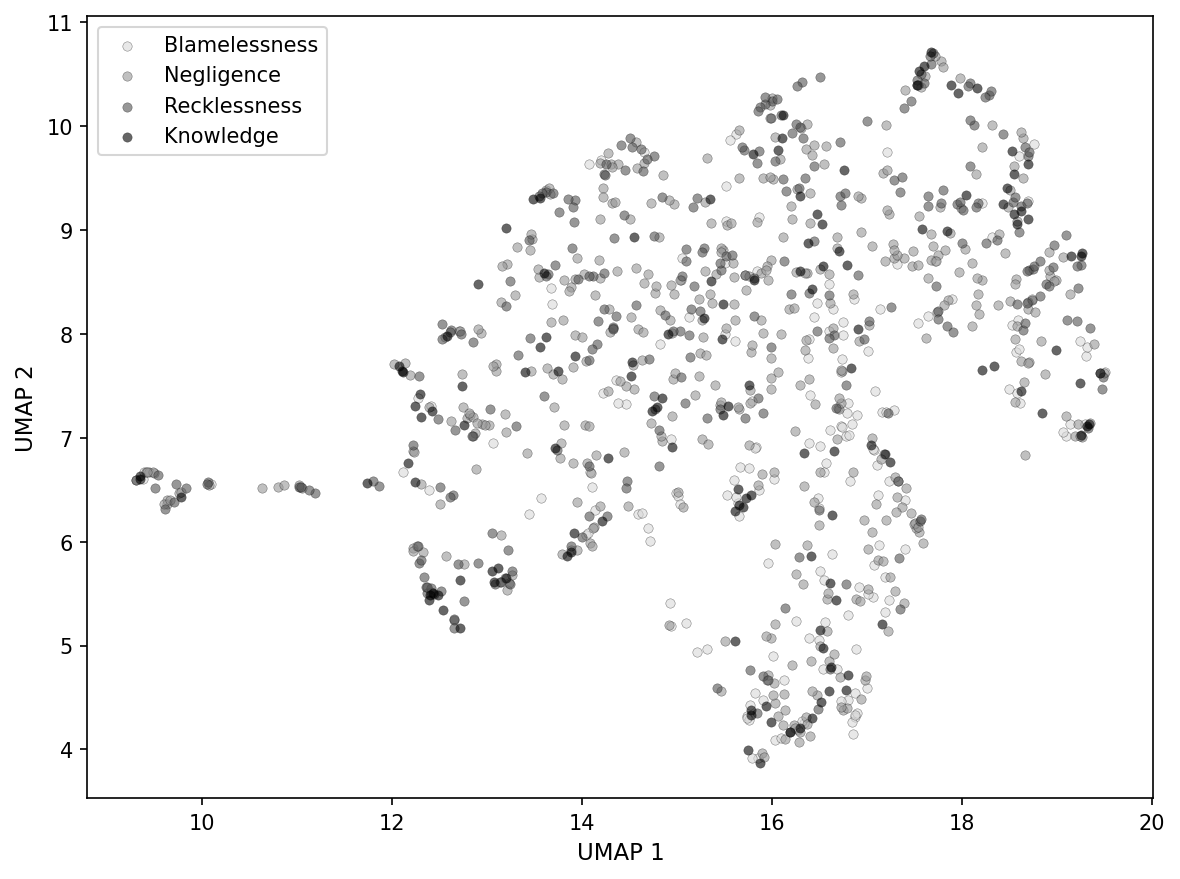

Saved: fig_justification_umap.pdf


In [23]:
# ── Embed justification texts with BGE (primary model) ──
if HAS_JUSTIFICATIONS:
    just_texts = d_just['justification_clean'].tolist()
    print(f"Embedding {len(just_texts)} justifications with BGE-large...")
    just_embeddings = st_model_bge.encode(just_texts, show_progress_bar=True,
                                          batch_size=32, normalize_embeddings=True)

    # ── UMAP on justifications ──
    reducer_just = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                              metric='cosine', random_state=SEED)
    just_umap = reducer_just.fit_transform(just_embeddings)
    d_just['just_umap_x'] = just_umap[:, 0]
    d_just['just_umap_y'] = just_umap[:, 1]

    # ── UMAP colored by judgment category ──
    gray_palette = {'Blamelessness': '#d9d9d9', 'Negligence': '#969696',
                    'Recklessness': '#525252', 'Knowledge': '#000000'}

    fig, ax = plt.subplots(figsize=(8, 6))
    for judgment in JUDGMENT_ORDER:
        subset = d_just[d_just['judgment'] == judgment]
        ax.scatter(subset['just_umap_x'], subset['just_umap_y'],
                   c=gray_palette[judgment], label=judgment,
                   s=20, alpha=0.6, edgecolors='black', linewidth=0.2)
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.legend(loc='best')
    plt.tight_layout()
    plt.savefig('fig_justification_umap.pdf', bbox_inches='tight')
    plt.show()
    print("Saved: fig_justification_umap.pdf")
else:
    print("Skipped: no justification text available.")

## 10. BERTopic & Text-to-Judgment Classification

**BERTopic** discovers latent themes in the justification texts using a pipeline of
sentence embeddings → UMAP → HDBSCAN → c-TF-IDF. Each justification is assigned
to a topic, and we examine how topics distribute across judgment categories.

**Text classification** tests whether a simple classifier can predict the mental
state judgment from the justification embedding alone. High accuracy here would mean
that participants' written reasoning contains reliable signals of their judgment,
beyond what the vignette features and risk slider capture.

Number of topics discovered: 3

 Topic  Count                       Name                                                                        Representation                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

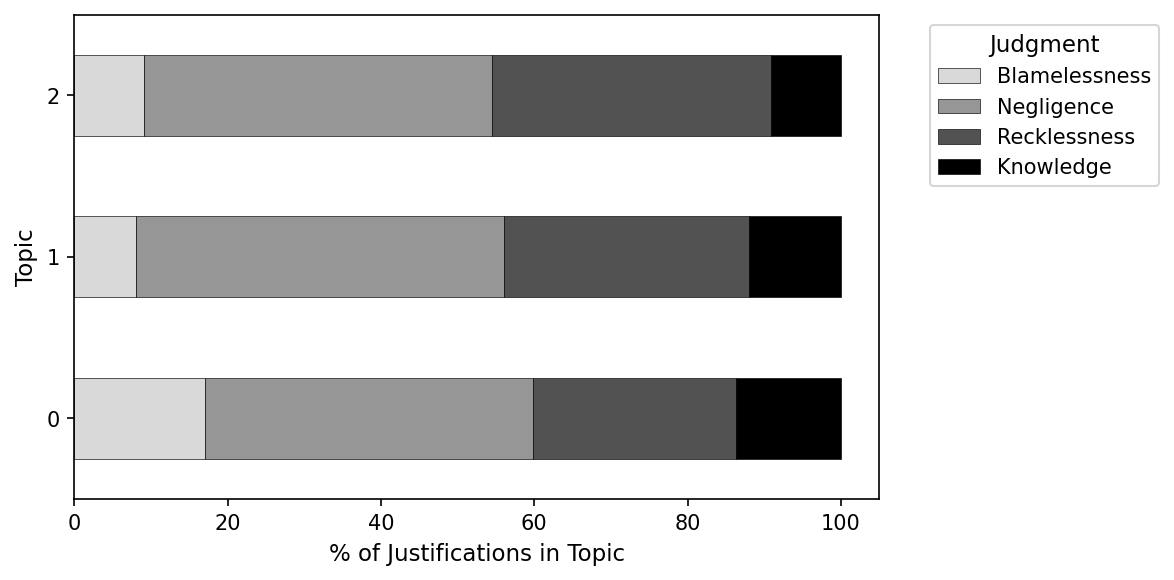

Saved: fig_bertopic_judgment.pdf


In [24]:
# ── BERTopic on justification texts ──
if HAS_JUSTIFICATIONS and BERTOPIC_AVAILABLE:
    topic_model = BERTopic(
        embedding_model=st_model_bge,
        umap_model=umap.UMAP(n_components=5, n_neighbors=15, min_dist=0.0,
                              metric='cosine', random_state=SEED),
        nr_topics='auto',
        verbose=False
    )
    topics, probs = topic_model.fit_transform(just_texts, just_embeddings)
    d_just['topic'] = topics

    # ── Topic summary table (ALL topics, not just top 15) ──
    topic_info = topic_model.get_topic_info()
    print(f"Number of topics discovered: {len(topic_info) - 1}")  # -1 for outlier
    print()
    print(topic_info.to_string(index=False))

    # ── Full topic descriptions: representative words for each topic ──
    print()
    print("═" * 60)
    print("Topic Descriptions (representative keywords)")
    print("═" * 60)
    for topic_id in sorted(topic_model.get_topics().keys()):
        if topic_id == -1:
            continue  # skip outlier topic
        words = topic_model.get_topic(topic_id)
        word_str = ", ".join([w for w, _ in words[:8]])
        # Get judgment distribution for this topic
        topic_judgments = d_just[d_just['topic'] == topic_id]['judgment'].value_counts(normalize=True)
        dominant = topic_judgments.index[0] if len(topic_judgments) > 0 else "N/A"
        pct = topic_judgments.iloc[0] * 100 if len(topic_judgments) > 0 else 0
        n = (d_just['topic'] == topic_id).sum()
        print(f"  Topic {topic_id:2d} (n={n:3d}, dominant={dominant} {pct:.0f}%): {word_str}")

    # ── Topic × judgment crosstab ──
    crosstab = pd.crosstab(d_just['topic'], d_just['judgment'],
                            normalize='index')[JUDGMENT_ORDER] * 100
    crosstab = crosstab.drop(index=-1, errors='ignore')

    if len(crosstab) > 1:
        fig, ax = plt.subplots(figsize=(8, max(4, len(crosstab) * 0.4)))
        crosstab.plot(kind='barh', stacked=True, ax=ax,
                      color=['#d9d9d9', '#969696', '#525252', '#000000'],
                      edgecolor='black', linewidth=0.3)
        ax.set_xlabel('% of Justifications in Topic')
        ax.set_ylabel('Topic')
        ax.legend(title='Judgment', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.savefig('fig_bertopic_judgment.pdf', bbox_inches='tight')
        plt.show()
        print("Saved: fig_bertopic_judgment.pdf")
elif HAS_JUSTIFICATIONS:
    print("BERTopic not available. Install with: pip install bertopic")
else:
    print("Skipped: no justification text available.")

### BERTopic with MiniLM (robustness comparison)

The BGE-large model produces high-dimensional (1024-d), semantically compressed
embeddings that concentrate justification texts into a dense region of embedding
space, yielding very few HDBSCAN clusters. To recover finer-grained thematic
structure, we rerun BERTopic using the smaller MiniLM model (384-d), whose
lower-dimensional embedding space provides more density variation for the
clustering algorithm to exploit.

This is not a limitation of BGE for other analyses (RSA, classification) — it
reflects the specific interaction between embedding geometry and density-based
clustering. For topic discovery in short free-text responses, smaller models
can outperform larger ones by producing more separable embedding landscapes.

Embedding justifications with MiniLM for topic modeling...


Batches:   0%|          | 0/33 [00:00<?, ?it/s]

MiniLM topics discovered: 23 (vs. 3 with BGE)

════════════════════════════════════════════════════════════
MiniLM Topic Descriptions (representative keywords)
════════════════════════════════════════════════════════════
  Topic  0 (n= 74, dominant=Negligence 42%): daniel, the, that, was, he, to, it, not
  Topic  1 (n= 67, dominant=Recklessness 36%): money, risk, payment, he, for, asked, ask, didn
  Topic  2 (n= 64, dominant=Negligence 41%): uncle, his, trusted, he, family, him, member, was
  Topic  3 (n= 59, dominant=Negligence 44%): bag, the, he, in, was, not, to, duffel
  Topic  4 (n= 55, dominant=Negligence 49%): package, he, the, to, was, not, it, there
  Topic  5 (n= 55, dominant=Recklessness 44%): border, across, to, the, he, there, it, is
  Topic  6 (n= 53, dominant=Negligence 45%): john, was, think, to, the, he, package, and
  Topic  7 (n= 46, dominant=Negligence 46%): david, his, it, uncle, to, the, would, and
  Topic  8 (n= 46, dominant=Negligence 52%): robert, the, that, wa

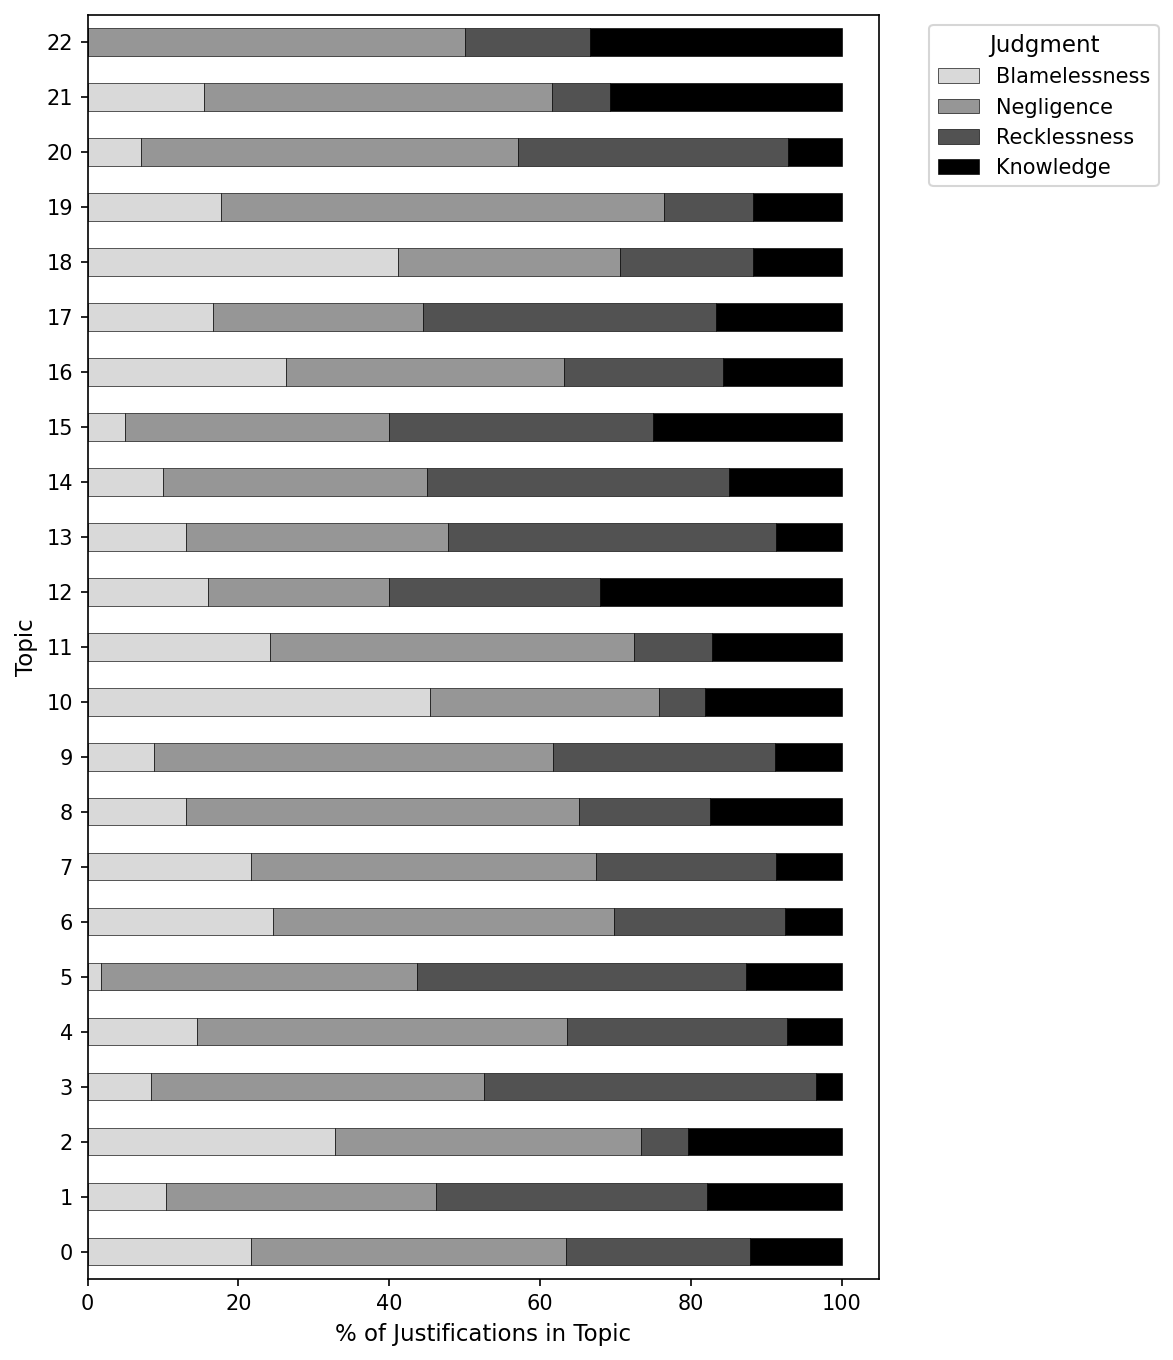

Saved: fig_bertopic_judgment_minilm.pdf


In [25]:
# ── BERTopic with MiniLM (for richer topic discovery) ──
if HAS_JUSTIFICATIONS and BERTOPIC_AVAILABLE:
    # Embed justifications with MiniLM for topic modeling
    print("Embedding justifications with MiniLM for topic modeling...")
    just_embeddings_mini = st_model_mini.encode(
        just_texts, show_progress_bar=True, batch_size=32, normalize_embeddings=True)

    topic_model_mini = BERTopic(
        embedding_model=st_model_mini,
        umap_model=umap.UMAP(n_components=5, n_neighbors=15, min_dist=0.0,
                              metric='cosine', random_state=SEED),
        nr_topics='auto',
        verbose=False
    )
    topics_mini, probs_mini = topic_model_mini.fit_transform(just_texts, just_embeddings_mini)
    d_just['topic_mini'] = topics_mini

    topic_info_mini = topic_model_mini.get_topic_info()
    print(f"MiniLM topics discovered: {len(topic_info_mini) - 1} (vs. {len(topic_info) - 1} with BGE)")
    print()

    # ── Full topic descriptions ──
    print("═" * 60)
    print("MiniLM Topic Descriptions (representative keywords)")
    print("═" * 60)
    for topic_id in sorted(topic_model_mini.get_topics().keys()):
        if topic_id == -1:
            continue
        words = topic_model_mini.get_topic(topic_id)
        word_str = ", ".join([w for w, _ in words[:8]])
        topic_judgments = d_just[d_just['topic_mini'] == topic_id]['judgment'].value_counts(normalize=True)
        dominant = topic_judgments.index[0] if len(topic_judgments) > 0 else "N/A"
        pct = topic_judgments.iloc[0] * 100 if len(topic_judgments) > 0 else 0
        n = (d_just['topic_mini'] == topic_id).sum()
        print(f"  Topic {topic_id:2d} (n={n:3d}, dominant={dominant} {pct:.0f}%): {word_str}")

    # ── Topic × judgment crosstab (MiniLM) ──
    crosstab_mini = pd.crosstab(d_just['topic_mini'], d_just['judgment'],
                                 normalize='index')[JUDGMENT_ORDER] * 100
    crosstab_mini = crosstab_mini.drop(index=-1, errors='ignore')

    if len(crosstab_mini) > 1:
        fig, ax = plt.subplots(figsize=(8, max(4, len(crosstab_mini) * 0.4)))
        crosstab_mini.plot(kind='barh', stacked=True, ax=ax,
                           color=['#d9d9d9', '#969696', '#525252', '#000000'],
                           edgecolor='black', linewidth=0.3)
        ax.set_xlabel('% of Justifications in Topic')
        ax.set_ylabel('Topic')
        ax.legend(title='Judgment', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.savefig('fig_bertopic_judgment_minilm.pdf', bbox_inches='tight')
        plt.show()
        print("Saved: fig_bertopic_judgment_minilm.pdf")
    else:
        print("Only 1 topic found with MiniLM — no crosstab to plot.")
else:
    print("Skipped: BERTopic or justification text not available.")

Text-only classification (BGE embeddings, 10-fold CV):
  Accuracy: 0.519 ± 0.037
  Cohen's κ: 0.237
  Chance level: 0.250 (uniform) or 0.429 (majority class)

               precision    recall  f1-score   support

Blamelessness       0.57      0.26      0.36       176
   Negligence       0.51      0.82      0.63       448
 Recklessness       0.54      0.46      0.49       279
    Knowledge       0.38      0.02      0.04       141

     accuracy                           0.52      1044
    macro avg       0.50      0.39      0.38      1044
 weighted avg       0.51      0.52      0.47      1044



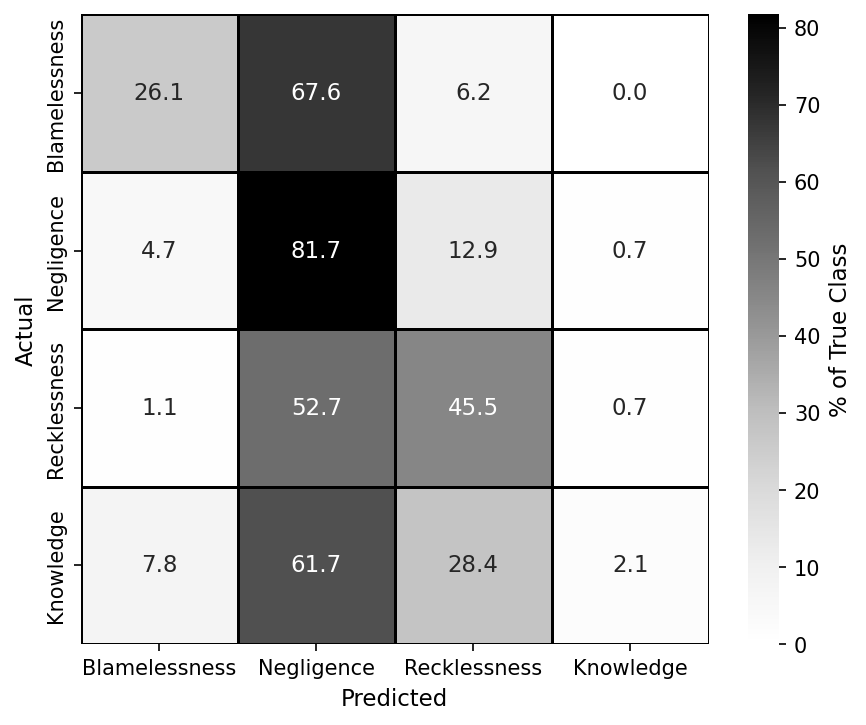

Saved: fig_text_classification_cm.pdf


In [26]:
# ── Text-to-judgment classification ──
# Can the justification embedding alone predict the mental state judgment?

if HAS_JUSTIFICATIONS:
    from sklearn.linear_model import LogisticRegression

    X_text = just_embeddings  # BGE 1024-dim embeddings
    y_text = d_just['culpability'].values

    lr = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED, n_jobs=-1)
    cv_text = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    text_scores = cross_val_score(lr, X_text, y_text, cv=cv_text, scoring='accuracy')
    y_text_pred = cross_val_predict(lr, X_text, y_text, cv=cv_text)

    print(f"Text-only classification (BGE embeddings, 10-fold CV):")
    print(f"  Accuracy: {text_scores.mean():.3f} ± {text_scores.std():.3f}")
    print(f"  Cohen's κ: {cohen_kappa_score(y_text, y_text_pred):.3f}")
    print(f"  Chance level: {1/4:.3f} (uniform) or "
          f"{pd.Series(y_text).value_counts(normalize=True).max():.3f} (majority class)")
    print()
    print(classification_report(y_text, y_text_pred, target_names=JUDGMENT_ORDER))

    # ── Confusion matrix ──
    cm_text = confusion_matrix(y_text, y_text_pred)
    cm_text_pct = cm_text.astype(float) / cm_text.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_text_pct, annot=True, fmt='.1f', cmap='Greys',
                xticklabels=JUDGMENT_ORDER, yticklabels=JUDGMENT_ORDER,
                cbar_kws={'label': '% of True Class'}, linewidths=0.5,
                linecolor='black', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.savefig('fig_text_classification_cm.pdf', bbox_inches='tight')
    plt.show()
    print("Saved: fig_text_classification_cm.pdf")
else:
    print("Skipped: no justification text available.")

## 11. Combined Feature + Text Model

If justification text is available, we test whether adding the text embedding
to the feature-based model improves classification accuracy. This tells us whether
participants' reasoning provides information about their judgment beyond what the
vignette features and risk slider already capture.

In [27]:
# ── Combined: features + text embedding ──
if HAS_JUSTIFICATIONS:
    X_combined = np.hstack([
        d_just[FEATURE_COLS_NO_SLIDER].values,  # 6 binary features (no slider)
        just_embeddings                           # BGE 1024-dim embeddings
    ])
    y_combined = d_just['culpability'].values

    rf_combined = RandomForestClassifier(
        n_estimators=500, max_depth=None, min_samples_leaf=5,
        class_weight='balanced', random_state=SEED, n_jobs=-1
    )

    cv_combined = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    combined_scores = cross_val_score(rf_combined, X_combined, y_combined,
                                      cv=cv_combined, scoring='accuracy')

    # Features-only baseline on the same subset (justification-having trials).
    X_feat_subset = d_just[FEATURE_COLS_NO_SLIDER].values
    feat_subset_scores = cross_val_score(
        RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_leaf=5,
                                class_weight='balanced', random_state=SEED, n_jobs=-1),
        X_feat_subset, y_combined, cv=cv_combined, scoring='accuracy'
    )

    # Features + slider baseline on same subset.
    X_full_subset = d_just[FEATURE_COLS].values
    full_subset_scores = cross_val_score(
        RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_leaf=5,
                                class_weight='balanced', random_state=SEED, n_jobs=-1),
        X_full_subset, y_combined, cv=cv_combined, scoring='accuracy'
    )

    print("═" * 60)
    print("Model Comparison (10-fold CV accuracy, justification subset)")
    print("═" * 60)
    print(f"  Features only (6 binary):   {feat_subset_scores.mean():.3f} ± {feat_subset_scores.std():.3f}")
    print(f"  Features + slider (7):      {full_subset_scores.mean():.3f} ± {full_subset_scores.std():.3f}")
    print(f"  Text embedding only (BGE):  {text_scores.mean():.3f} ± {text_scores.std():.3f}")
    print(f"  Features + text (6 + BGE):  {combined_scores.mean():.3f} ± {combined_scores.std():.3f}")
    print()

    # Statistical comparisons
    t1, p1 = stats.ttest_rel(combined_scores, feat_subset_scores)
    t2, p2 = stats.ttest_rel(combined_scores, full_subset_scores)
    print(f"  Combined vs features-only:    t = {t1:.2f}, p = {p1:.4f}")
    print(f"  Combined vs features+slider:  t = {t2:.2f}, p = {p2:.4f}")
    print()
    print("  Interpretation: If combined > features-only, the justification text")
    print("  contains judgment-relevant information beyond objective stimulus features.")
    print("  If combined ≈ features+slider, the text captures similar variance as")
    print("  the subjective risk rating — both reflect the participant's reasoning.")
else:
    print("Skipped: no justification text available.")

════════════════════════════════════════════════════════════
Model Comparison (10-fold CV accuracy, justification subset)
════════════════════════════════════════════════════════════
  Features only (6 binary):   0.315 ± 0.051
  Features + slider (7):      0.470 ± 0.062
  Text embedding only (BGE):  0.519 ± 0.037
  Features + text (6 + BGE):  0.531 ± 0.042

  Combined vs features-only:    t = 13.99, p = 0.0000
  Combined vs features+slider:  t = 3.83, p = 0.0040

  Interpretation: If combined > features-only, the justification text
  contains judgment-relevant information beyond objective stimulus features.
  If combined ≈ features+slider, the text captures similar variance as
  the subjective risk rating — both reflect the participant's reasoning.


## 12. Summary of Generated Figures

All figures are saved as PDFs in the current working directory. Grayscale throughout,
no titles (titles go in manuscript figure captions).

In [28]:
# ── List all generated figures ──
import glob
pdfs = sorted(glob.glob('fig_*.pdf'))
print(f"Generated {len(pdfs)} publication figures:")
for f in pdfs:
    size_kb = os.path.getsize(f) / 1024
    print(f"  {f} ({size_kb:.0f} KB)")

# ── Copy to Drive for persistence ──
OUTPUT_DIR = "/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Mens Rea /Analysis/NLP/Figures/Colab"
os.makedirs(OUTPUT_DIR, exist_ok=True)

import shutil
for f in pdfs:
    shutil.copy2(f, os.path.join(OUTPUT_DIR, f))
    print(f"  Copied {f} → Drive")

print(f"\nAll figures saved to: {OUTPUT_DIR}")

Generated 18 publication figures:
  fig_bertopic_judgment.pdf (13 KB)
  fig_bertopic_judgment_minilm.pdf (17 KB)
  fig_embedding_feature_distances.pdf (16 KB)
  fig_justification_umap.pdf (32 KB)
  fig_rf_confusion_matrix.pdf (22 KB)
  fig_rsa_scatter.pdf (90 KB)
  fig_shap_bar_global.pdf (20 KB)
  fig_shap_blamelessness.pdf (98 KB)
  fig_shap_class_heatmap.pdf (20 KB)
  fig_shap_dependence.pdf (55 KB)
  fig_shap_importance_bar.pdf (15 KB)
  fig_shap_interactions.pdf (19 KB)
  fig_shap_knowledge.pdf (127 KB)
  fig_shap_negligence.pdf (118 KB)
  fig_shap_recklessness.pdf (102 KB)
  fig_text_classification_cm.pdf (17 KB)
  fig_umap_by_feature.pdf (23 KB)
  fig_umap_vignette_space.pdf (39 KB)
  Copied fig_bertopic_judgment.pdf → Drive
  Copied fig_bertopic_judgment_minilm.pdf → Drive
  Copied fig_embedding_feature_distances.pdf → Drive
  Copied fig_justification_umap.pdf → Drive
  Copied fig_rf_confusion_matrix.pdf → Drive
  Copied fig_rsa_scatter.pdf → Drive
  Copied fig_shap_bar_global.

In [29]:
# ── Session info ──
import sys
print(f"Python: {sys.version}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {__import__('sklearn').__version__}")
print(f"SHAP: {shap.__version__}")
print(f"Sentence-Transformers: {__import__('sentence_transformers').__version__}")
print(f"UMAP: {umap.__version__}")
if BERTOPIC_AVAILABLE:
    print(f"BERTopic: {__import__('bertopic').__version__}")

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
NumPy: 2.0.2
Pandas: 2.2.2
Scikit-learn: 1.6.1
SHAP: 0.50.0
Sentence-Transformers: 5.2.3
UMAP: 0.5.11
BERTopic: 0.17.4


In [31]:
import nbformat
from google.colab import files

# 1. Define file paths
# Make sure this matches your actual file path in Drive
original_file = "/content/drive/MyDrive/DGK Lab/Castrellon Lab/DGK Lab - Mens Rea /Analysis/NLP/MPC_NLP_SHAP_Analysis_2.0.ipynb"
cleaned_file = "MPC_NLP_SHAP_Analysis_New_CleanedforHTML_2.0.ipynb"

# 2. Load the notebook
with open(original_file, "r", encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

# 3. DEEP CLEAN: Remove widget metadata from the global notebook settings
# This is likely the missing step causing the KeyError: 'state'
if 'widgets' in nb.metadata:
    del nb.metadata['widgets']

# 4. CLEAN CELLS: Remove widget outputs from individual cells
for cell in nb.cells:
    if "outputs" in cell:
        new_outputs = []
        for output in cell["outputs"]:
            # If the output has data, check if it's a widget
            if "data" in output:
                # We want to keep the output unless it is ONLY a widget
                # If it has other data (like text/png), just remove the widget part
                if "application/vnd.jupyter.widget-view+json" in output["data"]:
                    del output["data"]["application/vnd.jupyter.widget-view+json"]

                    # If the output is now empty (was only a widget), don't keep it
                    if not output["data"]:
                        continue
            new_outputs.append(output)
        cell["outputs"] = new_outputs

# 5. Save the deep-cleaned version
with open(cleaned_file, "w", encoding="utf-8") as f:
    nbformat.write(nb, f)

# 6. Convert and Download
print("Converting to HTML...")
!jupyter nbconvert --to html "MPC_NLP_SHAP_Analysis_New_CleanedforHTML_2.0.ipynb"

print("Downloading...")
files.download("MPC_NLP_SHAP_Analysis_New_CleanedforHTML_2.0.html")

Converting to HTML...
[NbConvertApp] Converting notebook MPC_NLP_SHAP_Analysis_New_CleanedforHTML_2.0.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 18 image(s).
[NbConvertApp] Writing 3026953 bytes to MPC_NLP_SHAP_Analysis_New_CleanedforHTML_2.0.html
Downloading...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>